# 연간 입력 기반 로보택시 실험 (v3: 도시별 M · 무작위 p, 손익 경계 근처 p)
**순서:**
1. 입력·기본 실험
2. 엣지 케이스
3. 공통 입력 민감도
4. 도시별 민감도
5. 시나리오

Baseline Model: Parameter Evidence and Setting Rationale」의 가정·산출값을 사용한다.
문헌을 참고한 **합성 입력**이며, 실제 세 도시의 보정된 데이터가 아니다.
초기 진입비는 한 번, 운영비·수요·용량은 진입 후 1년으로 평가한다.



## 실행 결과 먼저 보기

**이번 입력:** $M_c$ = A 577,908,105 / B 770,544,140 / C 963,180,175 건/년, $p_c^s$는 {0.002, 0.005, 0.01, 0.02}에서 무작위 추출(10개 시나리오, seed 2026; 값은 1/10),

- **수요와 용량이 같은 규모다:** 수요가 도시 최대 용량(8,760×500 = 4,380,000건)과 같아지는 p는 A 0.0076, B 0.0057, C 0.0045로 후보값 범위 안에 있다. 도시 최대 용량을 넘는 시나리오 비율은 A 50%, B 50%, C 80%다.
- **기본 최적 배치:** 세 도시 모두 진입. 대표해 **(132, 368, 500)**. A는 132대로 고정되고, B 368~439대·C 429~500대 사이(B+C = 868)에서 **72개 동률**.
- **처리량:** 평균 7,932,603건/년; 처리율 **34.93%**, 활용률 90.6%, 평균 유휴 827,397건.
- **목적함수:** 166,263,859 USD; 미진입 기준 227,117,885 USD; 미진입 대비 개선 **60,854,026 USD**.
- **배치의 논리:** c+=0이므로 차량 한 대의 기대 순가치는 87,600 × P(수요 > 배치 용량) − 7,972 USD다. A는 131대까지 모든 시나리오에서 수요가 남아 79,628 USD, 132번째는 78,117 USD, 133대부터는 7/10 시나리오만 남아 53,348 USD다. B(176~439대)와 C(220~500대)는 8/10 시나리오에서 수요가 남아 62,108 USD다. 그래서 1,000대는 A 132 + (B, C) 868로 나뉘고, B·C 구간의 한계가치가 같아 동률이 생긴다.
- **A 진입은 근소하다:** (0,500,500)보다 392,967 USD 유리할 뿐이다. 공통 F가 3.72M~3.94M USD 사이의 어느 값을 넘으면 A는 제외된다(F 민감도).
- **이제 수요·용량 입력에 배치가 반응한다:** M 배율 1.0625 이상 또는 p 배율 1.25 → (0,500,500); q̄ 750 이상 → (0,440,560); Q 900 → (0,400,500), 1,500 → (500,500,500); κ 8,212.5 이하의 조사점 → (0,500,500); c− 5 → (0,500,500), 2 → (0,0,500); 변동성 배율 α 0.7 이하 → (0,500,500).
- **시나리오의 가치:** 평균 수요 하나로 푼 배치를 10개 시나리오에서 평가하면 0.39M~8.14M USD의 추가비용이 난다(v2에서는 0).
- **표본 안정성:** 50개 표본에서는 시드에 따라 배치가 달라지고 공통 분포 추가비용이 최대 1.73M USD다. 500개 표본에서는 5개 시드 모두 추가비용 0이다.
- **검증:** 작은 전수열거 8개, 엣지 케이스 8개(입력 규모와 무관한 성질로 검사), MILP–DP 대조 210회, 50·100·500개 시나리오 × 5개 시드.

세 도시의 실제 최적 배치를 추정한 결과가 아니라 제공 문서의 합성 설정에 대한 결과이다.


In [ ]:
import importlib.util, sys, subprocess
packages = {'numpy':'numpy', 'pandas':'pandas', 'scipy':'scipy>=1.9',
            'matplotlib':'matplotlib', 'IPython':'ipython'}
missing = [p for m,p in packages.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
from copy import deepcopy
from itertools import product
import hashlib, json, html
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import coo_matrix
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown, HTML
fonts={f.name for f in font_manager.fontManager.ttflist}
kfont=next((f for f in ['Malgun Gothic','NanumGothic','Noto Sans CJK KR','AppleGothic'] if f in fonts),None)
plt.rcParams.update({'font.family':kfont or 'DejaVu Sans','axes.unicode_minus':False,
                     'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110})
def L(ko,en): return ko if kfont else en
def note(s): display(Markdown(s))
def show(title,df):
    note('**'+title+'**');display(df)
def detail(title,df):
    display(HTML('<details><summary>'+html.escape(title)+'</summary>'+df.to_html(index=False,float_format=lambda x:f'{x:,.4f}')+'</details>'))
FIGURES=[]
def showfig(fig,name):
    fig.tight_layout();FIGURES.append((name,fig));display(fig);plt.close(fig)
COLORS=['#2563a6','#c98a21','#39796b']

## 1. 기본값 실험
### 1-1. 입력과 출처의 성격
시장규모 $M_c$는 도시별로 다르며(기준값의 0.75·1·1.25배), 선택확률 $p_c^s$는 {0.002, 0.005, 0.01, 0.02}에서 무작위로 정한다.
비용·생산성 입력(F, K, κ, c+, c−, q̄)은 세 도시가 같다. 따라서 도시 간 차이는 **수요 쪽에만** 있다.


In [ ]:
cities=['A','B','C']
M=np.array([577_908_105.,770_544_140.,963_180_175.])
kappa=np.full(3,8_760.)
qbar=np.full(3,500,dtype=int)
F=np.full(3,3_500_000.)
K=np.full(3,7_972.)
c_plus=np.zeros(3)
c_minus=np.full(3,10.)
Q=1_000
P_LEVELS=np.array([.002,.005,.01,.02]);S=10;P_SEED=2026
p=np.random.default_rng(P_SEED).choice(P_LEVELS,size=(S,3))   # 도시·시나리오별 독립 균등 추출
S,C=p.shape
probability=np.full(S,1/S)
D=p*M
BASE={k:np.asarray(globals()[k]).copy() for k in ['M','kappa','qbar','F','K','c_plus','c_minus','p']}
BASE['Q']=Q
input_specs=[
 ('M','건/년','기준값 770,544,140 (= 38,527,207 / 0.05)의 0.75·1·1.25배; 실험용 대리값'),
 ('kappa','건/대·년','24 × 365; 실제 운행량 참고이며 물리적 최대용량의 관측값은 아님'),
 ('qbar','대','도시당 500대: 연구자 가정'),
 ('F','USD/도시 진입','(300,000 + 2,500,000) × 1.25; 추가 25%는 가정'),
 ('K','USD/대·년','4,334 + 1,131 + 1,694 + 813; 개인 차량 소유비 참고'),
 ('c_plus','USD/유휴 용량 1건','추가 유휴 손실 없음: 가정'),
 ('c_minus','USD/미충족 1건','가정한 수입 18 − 가변비 8; 실제 공헌이익 추정치 아님')]
show('도시별 입력',pd.DataFrame([{'입력':key,'단위':unit,**dict(zip(cities,BASE[key])),'근거·한계':why} for key,unit,why in input_specs]))
show('공통 설정',pd.DataFrame([
 ('총 차량 Q',Q),('시나리오 수',S),('시나리오 발생확률',f'각각 1/{S}'),
 ('평가기간','진입 후 1년; F 초기 1회, K 연간'),
 ('선택확률 p','{0.002, 0.005, 0.01, 0.02}에서 도시·시나리오별 독립 균등 추출 (seed 2026; 추출 패턴은 v2와 동일)'),
 ('수요 생성','D = M × p'),
 ('운영 가정','시나리오 공통 y,q / 도시 간 이동·공유 없음')],columns=['항목','설정']))
scen=pd.DataFrame(np.column_stack([p,D]),columns=['p_A','p_B','p_C','D_A','D_B','D_C']);scen.insert(0,'시나리오',np.arange(1,S+1))
show(f'공동 시나리오: p는 선택확률, 1/{S}은 상황의 발생확률',scen)
show('후보값별 추출 횟수 (도시별)',pd.DataFrame({f'p={lvl:g}':[int((p[:,c]==lvl).sum()) for c in range(3)] for lvl in P_LEVELS},index=cities))
assert np.allclose(M,770_544_140*np.array([.75,1.,1.25]))
assert 24*365 == kappa[0] and (300_000+2_500_000)*1.25 == F[0]
assert 4334+1131+1694+813 == K[0]
assert p.shape==(10,3) and set(np.unique(p).tolist())<=set(P_LEVELS.tolist())

k=np.arange(1,501)
for c in range(3):
    inc=(np.minimum(D[:,[c]],kappa[c]*k)-np.minimum(D[:,[c]],kappa[c]*(k-1))).mean(axis=0)
    val=pd.Series(c_minus[c]*inc-K[c],index=k)
    print(cities[c]); print(val[val.diff().abs().fillna(1)>0.5].round(0))  # 가치가 바뀌는 지점만 출력


**도시별 입력**

,입력,단위,A,B,C,근거·한계
0,M,건/년,577908105.0,770544140.0,963180175.0,"기준값 770,544,140 (= 38,527,207 / 0.05)의 0.75·1·..."
1,kappa,건/대·년,8760.0,8760.0,8760.0,24 × 365; 실제 운행량 참고이며 물리적 최대용량의 관측값은 아님
2,qbar,대,500.0,500.0,500.0,도시당 500대: 연구자 가정
3,F,USD/도시 진입,3500000.0,3500000.0,3500000.0,"(300,000 + 2,500,000) × 1.25; 추가 25%는 가정"
4,K,USD/대·년,7972.0,7972.0,7972.0,"4,334 + 1,131 + 1,694 + 813; 개인 차량 소유비 참고"
5,c_plus,USD/유휴 용량 1건,0.0,0.0,0.0,추가 유휴 손실 없음: 가정
6,c_minus,USD/미충족 1건,10.0,10.0,10.0,가정한 수입 18 − 가변비 8; 실제 공헌이익 추정치 아님


**공통 설정**

,항목,설정
0,총 차량 Q,1000
1,시나리오 수,10
2,시나리오 발생확률,각각 1/10
3,평가기간,"진입 후 1년; F 초기 1회, K 연간"
4,선택확률 p,"{0.002, 0.005, 0.01, 0.02}에서 도시·시나리오별 독립 균등 추출..."
5,수요 생성,D = M × p
6,운영 가정,"시나리오 공통 y,q / 도시 간 이동·공유 없음"


**공동 시나리오: p는 선택확률, 1/10은 상황의 발생확률**

,시나리오,p_A,p_B,p_C,D_A,D_B,D_C
0,1,0.020,0.002,0.002,1.155816e+07,1541088.28,1.926360e+06
1,2,0.010,0.005,0.005,5.779081e+06,3852720.70,4.815901e+06
2,3,0.002,0.005,0.010,1.155816e+06,3852720.70,9.631802e+06
3,4,0.005,0.020,0.020,2.889541e+06,15410882.80,1.926360e+07
4,5,0.010,0.020,0.010,5.779081e+06,15410882.80,9.631802e+06
5,6,0.002,0.020,0.010,1.155816e+06,15410882.80,9.631802e+06
6,7,0.002,0.005,0.002,1.155816e+06,3852720.70,1.926360e+06
7,8,0.020,0.010,0.020,1.155816e+07,7705441.40,1.926360e+07
8,9,0.005,0.010,0.010,2.889541e+06,7705441.40,9.631802e+06
9,10,0.020,0.002,0.010,1.155816e+07,1541088.28,9.631802e+06


**후보값별 추출 횟수 (도시별)**

,p=0.002,p=0.005,p=0.01,p=0.02
A,3,2,2,3
B,2,3,2,3
C,2,1,5,2


A
1      79628.0
132    78117.0
133    53348.0
330    50829.0
331    35828.0
dtype: float64
B
1      79628.0
176    78285.0
177    62108.0
440    57070.0
441    35828.0
dtype: float64
C
1      79628.0
220    77949.0
221    62108.0
dtype: float64


### 1-2. 수요와 용량 규모부터 확인
이 확인은 최적화 결과를 미리 정하는 과정이 아니다. 결과가 왜 움직이거나 움직이지 않는지 해석할 준비이다.
$$D_c^s=M_cp_c^s,\quad T_c^s=\min(D_c^s,\kappa_cq_c).$$
$$\text{처리율}(\%)=\frac{\frac1{|S|}\sum_s\sum_cT_c^s}{\frac1{|S|}\sum_s\sum_cD_c^s}\times100.$$
$$Z_0=\frac1{|S|}\sum_s\sum_cc_c^-D_c^s,\quad
Z=\sum_cF_cy_c+\sum_cK_cq_c+\frac1{|S|}\sum_s\sum_c(c_c^+O_c^s+c_c^-U_c^s),\quad
\text{개선액}=Z_0-Z.$$
수요가 0이면 처리율은 정의하지 않는다. 비용은 USD, 수요와 처리량은 연간 건수이다.

**수요와 최대 공급 비교**

,도시,최소 시나리오 수요,최대 시나리오 수요,평균 수요,도시 최대 용량,평균 수요/차량 용량,최소 수요/도시 최대 용량,용량과 같아지는 p (κq̄/M)
0,A,1155816.21,11558162.1,5.547918e+06,4380000.0,633.323951,0.263885,0.007579
1,B,1541088.28,15410882.8,7.628387e+06,4380000.0,870.820432,0.351847,0.005684
2,C,1926360.35,19263603.5,9.535484e+06,4380000.0,1088.525540,0.439808,0.004547


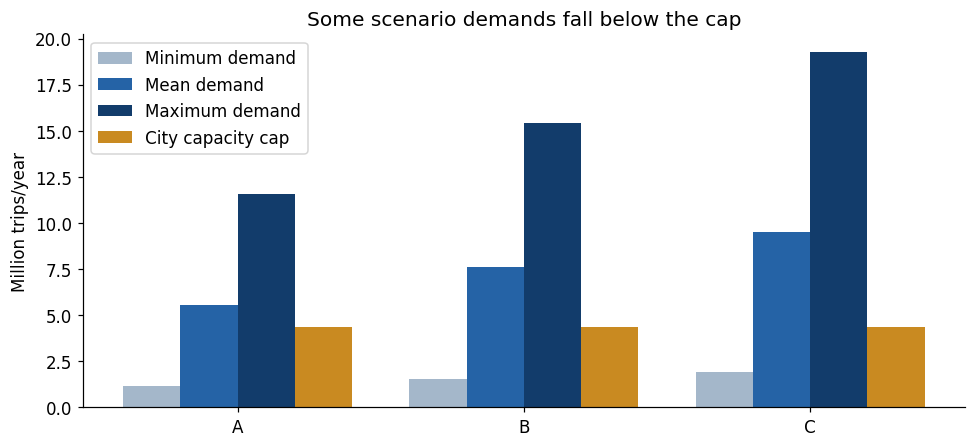

평균 수요를 도시별로 맞추는 데 필요한 차량은 정수 반올림 전 **2,592.7대**이다. 총차량 한도는 1,000대, 도시 상한 합계는 1,500대이다.

가장 작은 수요는 시나리오 3의 도시 A (p=0.002)에서 1,155,816건으로, 도시 최대 용량 4,380,000건의 **0.26배**이다. 수요가 용량과 같아지는 p는 도시별로 A 0.0076, B 0.0057, C 0.0045이며, 후보값 0.002~0.02의 범위 안에 있다.

일부 시나리오·도시에서 수요가 용량보다 작으므로 유휴 용량이 생길 수 있다.

In [ ]:
cap=kappa*qbar
scale_table=pd.DataFrame({'도시':cities,'최소 시나리오 수요':D.min(axis=0),'최대 시나리오 수요':D.max(axis=0),
    '평균 수요':D.mean(axis=0),'도시 최대 용량':cap,
    '평균 수요/차량 용량':D.mean(axis=0)/kappa,
    '최소 수요/도시 최대 용량':D.min(axis=0)/cap,
    '용량과 같아지는 p (κq̄/M)':cap/M})
show('수요와 최대 공급 비교',scale_table)
SHORTAGE=bool((D.min(axis=0)>=cap).all())   # 모든 시나리오·도시에서 수요 ≥ 도시 최대 용량
fig,ax=plt.subplots(figsize=(9,4.2))
x=np.arange(C);w=.2
for dx,vals,label,color in [(-1.5*w,D.min(axis=0),L('최소 수요','Minimum demand'),'#a4b7ca'),
 (-.5*w,D.mean(axis=0),L('평균 수요','Mean demand'),'#2563a6'),
 (.5*w,D.max(axis=0),L('최대 수요','Maximum demand'),'#123c6b'),
 (1.5*w,cap,L('도시 최대 용량','City capacity cap'),'#c98a21')]:
    ax.bar(x+dx,vals/1e6,w,label=label,color=color)
ax.set_xticks(x,cities);ax.set_ylabel(L('백만 건/년','Million trips/year'));ax.legend()
ax.set_title(L('최소 수요도 도시 최대 용량보다 크다','Even minimum demand exceeds each city capacity cap') if SHORTAGE
             else L('일부 시나리오에서 수요가 용량보다 작다','Some scenario demands fall below the cap'))
showfig(fig,'01_scale')
smin=np.unravel_index(D.argmin(),D.shape)
note(f"평균 수요를 도시별로 맞추는 데 필요한 차량은 정수 반올림 전 **{(D.mean(axis=0)/kappa).sum():,.1f}대**이다. "
     f"총차량 한도는 {Q:,}대, 도시 상한 합계는 {qbar.sum():,}대이다.")
note(f"가장 작은 수요는 시나리오 {smin[0]+1}의 도시 {cities[smin[1]]} (p={p[smin]:g})에서 {D.min():,.0f}건으로, "
     f"도시 최대 용량 {cap[0]:,.0f}건의 **{D.min()/cap[0]:.2f}배**이다. "
     f"수요가 용량과 같아지는 p는 도시별로 {', '.join(f'{cc} {v:.4f}' for cc,v in zip(cities,cap/M))}이며, 후보값 {P_LEVELS.min():g}~{P_LEVELS.max():g}의 범위 안에 있다.")
note('현재는 **모든 시나리오·도시에서 공급 부족**인 구간이다.' if SHORTAGE else '일부 시나리오·도시에서 수요가 용량보다 작으므로 유휴 용량이 생길 수 있다.')


### 1-3. 최적화와 독립 검증 함수
MILP는 기존의 y,q,O,U와 제약식을 그대로 사용한다. 큰 수의 계산을 안정화하기 위해
솔버 내부에서만 통행과 금액을 백만 단위로 바꾸며, 결과는 원래 단위로 환산한다.

작은 사례처럼 모든 (y,q)를 나열하면 규모가 너무 커지므로, 독립 검증은 **정수 차량 수별 동적계획법(DP)**을 쓴다.
각 도시·차량 수의 처리량으로 이익을 직접 계산하고, 총차량 한도 내 모든 배치를 비교하는 정확한 알고리즘이다.
DP 자체는 작은 사례 전수열거와 먼저 비교한다. MILP와 DP는 목적함수 행렬을 공유하지 않는다.

**복수 최적해:** 모든 최적 q의 수와 도시별 최소·최대 배치를 계산한다. 대규모 동률 집합은 처음 12개만 표시한다.
F=0인 경우 q=0인 도시의 불필요한 y=1은 배치의 별도 해로 세지 않는다.
대표해는 진입 도시 수가 적은 것, 이후 q의 사전순으로 결정한다. 성과를 보고 사후에 고르지 않는다.

In [ ]:
TOL_GAIN=1e-5  # DP의 이익 동률 판정: USD 절대 오차
TOL_USD=.05   # MILP/DP/직접 재계산 간 USD 절대 허용차
SOLVE_LOG=[]; CACHE={}
def validate(data):
    n=len(data['M']);assert n==3, '이 노트북은 세 도시 실험용입니다.'
    for key in ['M','kappa','qbar','F','K','c_plus','c_minus']:
        a=np.asarray(data[key]);assert a.shape==(n,) and np.isfinite(a).all() and (a>=0).all(),key
    assert np.equal(data['qbar'],np.floor(data['qbar'])).all()
    assert isinstance(data['Q'],(int,np.integer)) and data['Q']>=0
    pp=np.asarray(data['p']);assert pp.ndim==2 and pp.shape[1]==n and len(pp)>0
    assert np.isfinite(pp).all() and ((pp>=0)&(pp<=1)).all()

def evaluate(data,q,y=None):
    qq=np.asarray(q,dtype=int);yy=(qq>0).astype(int) if y is None else np.asarray(y,dtype=int)
    assert ((yy==0)|(yy==1)).all() and (qq>=0).all()
    assert (qq<=data['qbar']*yy).all() and qq.sum()<=data['Q']
    demand=data['p']*data['M'];capacity=data['kappa']*qq
    served=np.minimum(demand,capacity);unused=np.maximum(capacity-demand,0);unmet=np.maximum(demand-capacity,0)
    comp=np.array([data['F']@yy,data['K']@qq,np.mean(unused@data['c_plus']),np.mean(unmet@data['c_minus'])])
    no_entry=float(np.mean(demand@data['c_minus']))
    # 개선액은 큰 두 금액의 차이 대신 처리 공헌이익에서 비용을 빼서 계산한다.
    gain=float(np.mean(served@data['c_minus'])-comp[:3].sum())
    ed=float(demand.sum(axis=1).mean());st=float(served.sum(axis=1).mean())
    return dict(q=tuple(qq),y=tuple(yy),components=comp,cost=float(comp.sum()),gain=gain,no_entry=no_entry,
        demand=ed,served=st,unmet=float(unmet.sum(axis=1).mean()),unused=float(unused.sum(axis=1).mean()),
        service_rate=st/ed if ed else np.nan,utilization=st/capacity.sum() if capacity.sum() else np.nan,
        D=demand,O=unused,U=unmet,capacity=capacity)

def dp_oracle(data):
    n=len(data['M']);B=min(int(data['Q']),int(sum(data['qbar'])))
    caps=np.minimum(data['qbar'],B).astype(int)
    gains=[]
    for c in range(n):
        qs=np.arange(caps[c]+1);dd=data['p'][:,c]*data['M'][c]
        cap=data['kappa'][c]*qs
        # 독립 계산: MILP의 O/U 행렬을 사용하지 않고 서비스 가치를 직접 계산한다.
        service=np.minimum(dd[:,None],cap).mean(axis=0)
        idle=np.maximum(cap-dd[:,None],0).mean(axis=0)
        gains.append(data['c_minus'][c]*service-data['c_plus'][c]*idle
                     -data['K'][c]*qs-data['F'][c]*(qs>0))
    best=np.full((n+1,B+1),-np.inf);best[n,0]=0
    counts=np.zeros((n+1,B+1),dtype=np.int64);counts[n,0]=1
    entries=np.full((n+1,B+1),n+1,dtype=int);entries[n,0]=0
    lo=np.full((n+1,B+1,n),np.inf);hi=np.full((n+1,B+1,n),-np.inf)
    lo[n,0]=0;hi[n,0]=0
    for i in range(n-1,-1,-1):
        for v in range(caps[i]+1):
            length=B-v+1;src=best[i+1,:length];valid=np.isfinite(src)
            cand=src+gains[i][v];dst=best[i,v:]
            better=valid&(cand>dst+TOL_GAIN)
            tied=valid&~better&(np.abs(cand-np.where(np.isfinite(dst),dst,0))<=TOL_GAIN)
            child=counts[i+1,:length];ec=entries[i+1,:length]+int(v>0)
            counts[i,v:][better]=child[better];counts[i,v:][tied]+=child[tied]
            entries[i,v:][better]=ec[better]
            entries[i,v:][tied]=np.minimum(entries[i,v:][tied],ec[tied])
            clo=lo[i+1,:length].copy();chi=hi[i+1,:length].copy();clo[:,i]=v;chi[:,i]=v
            lo[i,v:][better]=clo[better];hi[i,v:][better]=chi[better]
            lo[i,v:][tied]=np.minimum(lo[i,v:][tied],clo[tied]);hi[i,v:][tied]=np.maximum(hi[i,v:][tied],chi[tied])
            dst[better]=cand[better]
    optimum=float(best[0].max());budgets=np.flatnonzero(np.abs(best[0]-optimum)<=TOL_GAIN)
    fewest=int(entries[0,budgets].min())
    def reconstruct(b):
        result=[]
        for i in range(n):
            for v in range(min(caps[i],b)+1):
                if (abs(gains[i][v]+best[i+1,b-v]-best[i,b])<=TOL_GAIN
                    and int(v>0)+entries[i+1,b-v]==entries[i,b]):
                    result.append(v);b-=v;break
            else:raise AssertionError('DP 경로 복원 실패')
        return tuple(result)
    rep=min(reconstruct(int(b)) for b in budgets if entries[0,b]==fewest)
    samples=[]
    def walk(i,b,path):
        if len(samples)>=12:return
        if i==n:
            samples.append(tuple(path));return
        for v in range(min(caps[i],b)+1):
            if abs(gains[i][v]+best[i+1,b-v]-best[i,b])<=TOL_GAIN:
                walk(i+1,b-v,path+[v])
                if len(samples)>=12:return
    for b in budgets:
        walk(0,int(b),[])
        if len(samples)>=12:break
    return dict(gain=optimum,q=rep,count=int(counts[0,budgets].sum()),samples=samples,
                q_min=lo[0,budgets].min(axis=0).astype(int),q_max=hi[0,budgets].max(axis=0).astype(int))

def solve(data,label=''):
    validate(data)
    key=hashlib.sha256(json.dumps({k:np.asarray(v).tolist() for k,v in data.items()},sort_keys=True).encode()).hexdigest()
    if key in CACHE:return CACHE[key]
    ns,nc=data['p'].shape;demand=data['p']*data['M']
    scale=1e6 if demand.max()>=1e6 else 1.0
    iy=np.arange(nc);iq=np.arange(nc,2*nc)
    io=np.arange(2*nc,2*nc+ns*nc).reshape(ns,nc)
    iu=np.arange(2*nc+ns*nc,2*nc+2*ns*nc).reshape(ns,nc);nv=2*nc+2*ns*nc
    cost=np.zeros(nv);cost[iy]=data['F']/scale;cost[iq]=data['K']/scale
    cost[io]=data['c_plus']/ns;cost[iu]=data['c_minus']/ns
    upper=np.full(nv,np.inf);upper[iy]=1;upper[iq]=data['qbar']
    integer=np.zeros(nv);integer[iy]=integer[iq]=1
    row_ids=[];cols=[];vals=[];lb=[];ub=[]
    def add(coefs,low,high):
        row=len(lb)
        for col,val in coefs.items():row_ids.append(row);cols.append(col);vals.append(val)
        lb.append(low);ub.append(high)
    for c in range(nc):add({int(iq[c]):1,int(iy[c]):-data['qbar'][c]},-np.inf,0)
    add({int(i):1 for i in iq},-np.inf,data['Q'])
    for s in range(ns):
        for c in range(nc):
            add({int(iq[c]):data['kappa'][c]/scale,int(io[s,c]):-1,int(iu[s,c]):1},demand[s,c]/scale,demand[s,c]/scale)
    A=coo_matrix((vals,(row_ids,cols)),shape=(len(lb),nv)).tocsc()
    res=milp(cost,integrality=integer,bounds=Bounds(np.zeros(nv),upper),
             constraints=LinearConstraint(A,lb,ub),options={'mip_rel_gap':0.,'time_limit':120.})
    assert res.status==0,(label,res.message)
    yy=np.rint(res.x[iy]).astype(int);qq=np.rint(res.x[iq]).astype(int)
    sm=evaluate(data,qq,yy);oracle=dp_oracle(data);rep=evaluate(data,oracle['q'])
    rawO=res.x[io]*scale;rawU=res.x[iu]*scale
    active=data['c_plus']+data['c_minus']>0
    checks={
        'MILP 정수':np.allclose(res.x[iq],qq,atol=1e-6,rtol=0) and np.allclose(res.x[iy],yy,atol=1e-6,rtol=0),
        '균형식':np.allclose(data['kappa']*qq-demand,rawO-rawU,atol=.001,rtol=0),
        'O/U 비음':bool((rawO>=-.001).all() and (rawU>=-.001).all()),
        '목적함수 재계산':abs(res.fun*scale-sm['cost'])<=TOL_USD,
        '독립 DP 일치':abs(sm['gain']-oracle['gain'])<=TOL_USD,
        'DP 대표해':abs(rep['gain']-oracle['gain'])<=TOL_USD,
        '서비스/수요 합계':np.allclose(np.minimum(demand,sm['capacity'])+sm['U'],demand,atol=.001,rtol=0),
        '양의 계수 O/U':np.allclose(rawO[:,active],sm['O'][:,active],atol=.001,rtol=0) and np.allclose(rawU[:,active],sm['U'][:,active],atol=.001,rtol=0),
        '개선액 항등식':abs(rep['no_entry']-rep['cost']-rep['gain'])<=TOL_USD}
    assert all(checks.values()),(label,checks)
    answer=dict(data=deepcopy(data),rep=rep,oracle=oracle,checks=checks,solver_q=tuple(qq),mip_gap=float(res.mip_gap))
    SOLVE_LOG.append({'label':label,'checks':checks,'cost':rep['cost'],'gain':rep['gain'],'gap':float(res.mip_gap)})
    CACHE[key]=answer;return answer

def report_row(a):
    r=a['rep'];o=a['oracle']
    return {'대표 배치':r['q'],'최적 q 개수':o['count'],'평균 수요':r['demand'],'평균 처리량':r['served'],
            '평균 미충족':r['unmet'],'평균 유휴':r['unused'],'처리율 (%)':100*r['service_rate'],
            '활용률 (%)':100*r['utilization'],'진입비':r['components'][0],'차량비':r['components'][1],
            '유휴 페널티':r['components'][2],'미충족 손실':r['components'][3],
            '목적함수':r['cost'],'미진입 기준':r['no_entry'],'개선액':r['gain'],
            '모든 최적 q의 도시별 최소':tuple(o['q_min']),'모든 최적 q의 도시별 최대':tuple(o['q_max'])}

### 1-4. DP를 작은 전수열거와 먼저 대조
아래 검사는 이번 대규모 결과를 정답으로 가정하지 않는다.
작은 사례 및 비용 0·수요 0·도시별 상한 변경의 정수 문제를 전수열거해 DP의 최적값·해 개수·배치 범위를 확인한다.

In [ ]:
small=deepcopy(BASE)
small.update(M=np.array([80.,100.,120.]),kappa=np.full(3,10.),qbar=np.full(3,2),Q=4,
             F=np.full(3,20.),K=np.full(3,5.),c_plus=np.zeros(3),c_minus=np.full(3,10.),
             p=np.array([[.05,.05,.05],[.2,.2,.2],[.5,.5,.5],[.8,.8,.8],[.05,.2,.5],
                         [.2,.5,.05],[.5,.05,.2],[.2,.5,.8],[.5,.8,.2],[.8,.2,.5]]))
small_tests=[{}, {'F':np.zeros(3)}, {'M':np.zeros(3)}, {'Q':0},
             {'c_minus':np.zeros(3)}, {'c_plus':np.full(3,15.)},
             {'F':np.zeros(3),'K':np.zeros(3),'c_minus':np.zeros(3)}, {'qbar':np.array([0,2,3])}]
for changes in small_tests:
    d=deepcopy(small);d.update(changes);o=dp_oracle(d)
    candidates=[evaluate(d,q) for q in product(*(range(int(v)+1) for v in d['qbar'])) if sum(q)<=d['Q']]
    best_gain=max(r['gain'] for r in candidates);opts=[r for r in candidates if abs(r['gain']-best_gain)<=TOL_GAIN]
    assert abs(o['gain']-best_gain)<=TOL_GAIN and o['count']==len(opts)
    assert np.array_equal(o['q_min'],np.min([r['q'] for r in opts],axis=0))
    assert np.array_equal(o['q_max'],np.max([r['q'] for r in opts],axis=0))
assert solve(small,'small regression')['rep']['q']==(0,2,2)
assert abs(solve(small)['rep']['cost']-858)<TOL_USD
note('**DP 전수열거 대조 8개 PASS; 작은 사례 MILP 목적함수 858 재현 PASS.**')

**DP 전수열거 대조 8개 PASS; 작은 사례 MILP 목적함수 858 재현 PASS.**

### 1-5. 연간 기본 결과
전수 범위를 축소하지 않고 MILP와 DP를 각각 실행한다. 대표해와 모든 동률 배치를 구분해서 읽는다.

**기본 결과**

,값
대표 배치,"(132, 368, 500)"
최적 q 개수,72
평균 수요,22711788.5265
평균 처리량,7932602.589
평균 미충족,14779185.9375
평균 유휴,827397.411
처리율 (%),34.927247
활용률 (%),90.554824
진입비,10500000.0
차량비,7972000.0


**도시별 기본 결과**

,도시,진입,차량,용량,평균 수요,평균 처리량,평균 미충족,평균 유휴
0,A,1,132,1156320.0,5.547918e+06,1156168.863,4.391749e+06,151.137
1,B,1,368,3223680.0,7.628387e+06,2887161.656,4.741225e+06,336518.344
2,C,1,500,4380000.0,9.535484e+06,3889272.070,5.646212e+06,490727.930


**기본 시나리오별 합계**

,시나리오,수요,처리량,미충족,유휴
0,1,1.502561e+07,4623768.63,1.040184e+07,4136231.37
1,2,1.444770e+07,8760000.00,5.687703e+06,0.00
2,3,1.464034e+07,8759496.21,5.880842e+06,503.79
3,4,3.756403e+07,8760000.00,2.880403e+07,0.00
4,5,3.082177e+07,8760000.00,2.206177e+07,0.00
5,6,2.619850e+07,8759496.21,1.743900e+07,503.79
6,7,6.934897e+06,6305856.56,6.290407e+05,2454143.44
7,8,3.852721e+07,8760000.00,2.976721e+07,0.00
8,9,2.022678e+07,8760000.00,1.146678e+07,0.00
9,10,2.273105e+07,7077408.28,1.565364e+07,1682591.72


**모든 최적 배치**

,q,cost,served,unused,gain
0,"(132, 368, 500)",1.662639e+08,7932602.589,827397.411,60854025.89
1,"(132, 369, 499)",1.662639e+08,7932602.589,827397.411,60854025.89
2,"(132, 370, 498)",1.662639e+08,7932602.589,827397.411,60854025.89
3,"(132, 371, 497)",1.662639e+08,7932602.589,827397.411,60854025.89
4,"(132, 372, 496)",1.662639e+08,7932602.589,827397.411,60854025.89
5,"(132, 373, 495)",1.662639e+08,7932602.589,827397.411,60854025.89
6,"(132, 374, 494)",1.662639e+08,7932602.589,827397.411,60854025.89
7,"(132, 375, 493)",1.662639e+08,7932602.589,827397.411,60854025.89
8,"(132, 376, 492)",1.662639e+08,7932602.589,827397.411,60854025.89
9,"(132, 377, 491)",1.662639e+08,7932602.589,827397.411,60854025.89


**도시별 배치 판단 근거**

,도시,배치 q,P(수요 > 배치 용량),마지막 한 대의 한계가치 (USD),"한 대 더 넣을 때 한계가치 (USD, Q 무시)",q̄대 배치 시 기대 처리량,q̄대 배치 시 진입비 전 기여 (USD),q̄대 배치 시 진입비 후 기여 (USD)
0,A,132,0.7,78116.63,53348.0,3114652.968,27160529.68,23660529.68
1,B,368,0.8,62108.00,62108.0,3654033.866,32554338.66,29054338.66
2,C,500,0.8,62108.00,NaN,3889272.070,34906720.70,31406720.70


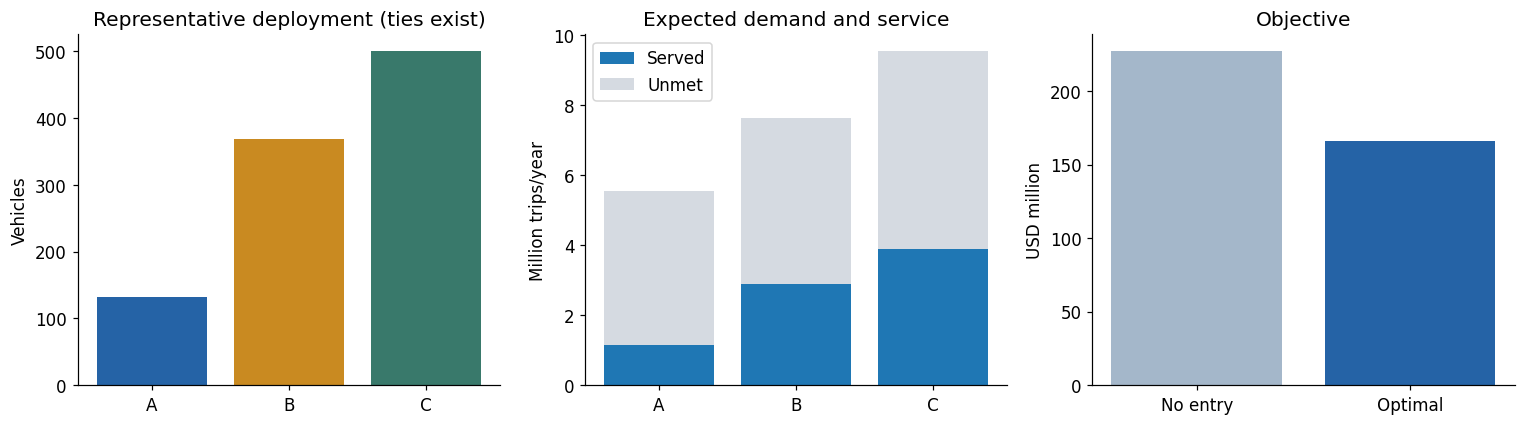

**기본 결과:** 처리율 34.927%, 활용률 90.6%, 목적함수 166,263,859 USD, 미진입 대비 개선 60,854,026 USD. **최적 배치 72개: (132, 368, 500), (132, 369, 499), (132, 370, 498), (132, 371, 497), (132, 372, 496), (132, 373, 495), (132, 374, 494), (132, 375, 493), (132, 376, 492), (132, 377, 491), (132, 378, 490), (132, 379, 489).** 대표해를 특정 도시의 우위로 해석하지 않는다.

c+=0이므로 차량 한 대의 기대 순가치는 c−·κ·P(수요 > 배치 용량) − K 이다. 시나리오가 10개이므로 이 확률은 0.1 단위로 움직이고, 한 시나리오에서만 수요가 남아도 한 대의 가치는 8,760 USD로 차량비 7,972 USD보다 크다. 따라서 각 도시는 "가장 큰 시나리오 수요를 채우는 데 필요한 대수"까지 차량을 원하고, 총차량 Q와 진입비 F가 도시 간 배분을 결정한다. 위 표의 한계가치와 q̄대 배치 시 기여를 비교하면 어떤 도시가 우선되는지 읽을 수 있다.

In [ ]:
baseline=solve(BASE,'annual baseline');b=baseline['rep']
y=np.array(b['y']);q=np.array(b['q']);capacity=b['capacity']
show('기본 결과',pd.DataFrame([report_row(baseline)]).T.rename(columns={0:'값'}))
show('도시별 기본 결과',pd.DataFrame({'도시':cities,'진입':y,'차량':q,'용량':capacity,
    '평균 수요':D.mean(axis=0),'평균 처리량':(D-b['U']).mean(axis=0),'평균 미충족':b['U'].mean(axis=0),'평균 유휴':b['O'].mean(axis=0)}))
show('기본 시나리오별 합계',pd.DataFrame({'시나리오':np.arange(1,S+1),'수요':D.sum(axis=1),
    '처리량':(D-b['U']).sum(axis=1),'미충족':b['U'].sum(axis=1),'유휴':b['O'].sum(axis=1)}))
ties=baseline['oracle']['samples']
show('모든 최적 배치',pd.DataFrame([{'q':qq,**{k:evaluate(BASE,qq)[k] for k in ['cost','served','unused','gain']}} for qq in ties]))
# 도시별 판단 근거: 차량 한 대의 기대 가치는 c− × κ × P(수요 > 배치 용량) − K 로 읽을 수 있다 (c+=0).
cap_bar=kappa*qbar
served_bar=np.minimum(D,cap_bar).mean(axis=0)
marg_last=c_minus*(np.minimum(D,kappa*q)-np.minimum(D,kappa*np.maximum(q-1,0))).mean(axis=0)-K
marg_next=c_minus*(np.minimum(D,kappa*(q+1))-np.minimum(D,kappa*q)).mean(axis=0)-K
city_value=pd.DataFrame({'도시':cities,'배치 q':q,
    'P(수요 > 배치 용량)':(D>capacity).mean(axis=0),
    '마지막 한 대의 한계가치 (USD)':np.where(q>0,marg_last,np.nan),
    '한 대 더 넣을 때 한계가치 (USD, Q 무시)':np.where(q<qbar,marg_next,np.nan),
    'q̄대 배치 시 기대 처리량':served_bar,
    'q̄대 배치 시 진입비 전 기여 (USD)':c_minus*served_bar-K*qbar,
    'q̄대 배치 시 진입비 후 기여 (USD)':c_minus*served_bar-K*qbar-F})
show('도시별 배치 판단 근거',city_value)
if SHORTAGE:
    assert baseline['oracle']['count']==3
    assert abs(b['gain']-(Q*(kappa[0]*c_minus[0]-K[0])-2*F[0]))<TOL_USD
fig,axes=plt.subplots(1,3,figsize=(14,4))
axes[0].bar(cities,q,color=COLORS);axes[0].set_ylabel(L('대','Vehicles'));axes[0].set_title(L('대표 배치 (다른 동률 해 있음)','Representative deployment (ties exist)') if baseline['oracle']['count']>1 else L('최적 배치 (유일)','Optimal deployment (unique)'))
axes[1].bar(cities,(D-b['U']).mean(axis=0)/1e6,label=L('처리','Served'))
axes[1].bar(cities,b['U'].mean(axis=0)/1e6,bottom=(D-b['U']).mean(axis=0)/1e6,color='#d5dae1',label=L('미충족','Unmet'))
axes[1].set_ylabel(L('백만 건/년','Million trips/year'));axes[1].legend();axes[1].set_title(L('기대 수요와 처리량','Expected demand and service'))
axes[2].bar([L('미진입','No entry'),L('최적','Optimal')],[b['no_entry']/1e6,b['cost']/1e6],color=['#a4b7ca','#2563a6'])
axes[2].set_ylabel('USD million');axes[2].set_title(L('목적함수','Objective'))
showfig(fig,'02_baseline')
note(f"**기본 결과:** 처리율 {b['service_rate']:.3%}, 활용률 {b['utilization']:.1%}, "
     f"목적함수 {b['cost']:,.0f} USD, 미진입 대비 개선 {b['gain']:,.0f} USD. "
     f"**최적 배치 {baseline['oracle']['count']}개: {', '.join(map(str,ties))}.** "
     +('대표해를 특정 도시의 우위로 해석하지 않는다.' if baseline['oracle']['count']>1 else '최적해가 유일하므로 도시 간 수요 차이가 배치에 반영되었다.'))
if SHORTAGE:
    note('모든 시나리오에서 세 도시 모두 수요가 용량을 넘으므로, 차량 한 대는 어디서든 8,760건을 처리한다. '
         '각 도시의 비용·생산성·공헌이익 계수가 같으므로 어느 두 도시를 선택해도 동일하다.')
else:
    note('c+=0이므로 차량 한 대의 기대 순가치는 c−·κ·P(수요 > 배치 용량) − K 이다. 시나리오가 10개이므로 이 확률은 0.1 단위로 움직이고, '
         f'한 시나리오에서만 수요가 남아도 한 대의 가치는 {c_minus[0]*kappa[0]*0.1:,.0f} USD로 차량비 {K[0]:,.0f} USD보다 크다. '
         '따라서 각 도시는 "가장 큰 시나리오 수요를 채우는 데 필요한 대수"까지 차량을 원하고, 총차량 Q와 진입비 F가 도시 간 배분을 결정한다. '
         '위 표의 한계가치와 q̄대 배치 시 기여를 비교하면 어떤 도시가 우선되는지 읽을 수 있다.')


## 2. 엣지 케이스
각 실험은 기본 입력의 복사본에서 시작한다. 작은 사례의 숫자 0·2·2나 858을 그대로 검사하지 않는다.
특히 E8은 문서 입력이 아니라 **정상 작동을 확인하기 위한 인위적 경계 조건**이다.

**엣지 케이스: 변경 조건과 검사**

,검사,조건,변경 입력,예상 성질,검사 결과
0,E1,가용 차량 없음,{'Q': 0},"모든 q=0, U=D, Z=Z0",PASS
1,E2,수요 없음,"{'M': array([0., 0., 0.])}","미진입, Z=0, O=U=0",PASS
2,E3,A 배치 금지,"{'qbar': array([ 0, 500, 500])}","A=0; B,C 배치는 국소 최적 (한 대 증감으로 개선 불가)",PASS
3,E4,미충족 손실 없음,"{'c_minus': array([0., 0., 0.])}","미진입, Z=0",PASS
4,E5,매우 큰 진입비,"{'F': array([2.27117886e+08, 2.27117886e+08, 2...",진입비가 전체 서비스 가치보다 커 미진입,PASS
5,E6,총차량 한도 완화,{'Q': 2000},"Q 비구속: 총 ≤ 1,500대, 개선액 ≥ 기본, 국소 최적",PASS
6,E7,진입비 없음,"{'F': array([0., 0., 0.])}",개선액 ≥ 기본; 총 ≤ Q,PASS
7,E8,수요=차량 한 대 용량,"{'p': array([[1.51581193e-05, 1.13685895e-05, ...","F도 0으로 바꿔 진입을 가능하게 함; 도시별 1대, O=U=0",PASS


**엣지 케이스: 배치와 서비스**

,검사,대표 배치,최적 q 개수,처리율 (%),평균 처리량,평균 미충족,평균 유휴
0,E1,"(0, 0, 0)",1,0.000000,0.000000e+00,2.271179e+07,0.000
1,E2,"(0, 0, 0)",1,NaN,0.000000e+00,0.000000e+00,0.000
2,E3,"(0, 500, 500)",1,33.213174,7.543306e+06,1.516848e+07,1216694.064
3,E4,"(0, 0, 0)",1,0.000000,0.000000e+00,2.271179e+07,0.000
4,E5,"(0, 0, 0)",1,0.000000,0.000000e+00,2.271179e+07,0.000
5,E6,"(500, 500, 500)",1,46.926991,1.065796e+07,1.205383e+07,2482041.096
6,E7,"(132, 368, 500)",72,34.927247,7.932603e+06,1.477919e+07,827397.411
7,E8,"(1, 1, 1)",1,100.000000,2.628000e+04,0.000000e+00,0.000


**엣지 케이스: 비용 분해 (USD)**

,검사,진입비,차량비,유휴 페널티,미충족 손실,목적함수,미진입 기준,개선액
0,E1,0.0,0.0,0.0,2.271179e+08,2.271179e+08,2.271179e+08,0.00
1,E2,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.00
2,E3,7000000.0,7972000.0,0.0,1.516848e+08,1.666568e+08,2.271179e+08,60461059.36
3,E4,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.00
4,E5,0.0,0.0,0.0,2.271179e+08,2.271179e+08,2.271179e+08,0.00
5,E6,10500000.0,11958000.0,0.0,1.205383e+08,1.429963e+08,2.271179e+08,84121589.04
6,E7,0.0,7972000.0,0.0,1.477919e+08,1.557639e+08,2.271179e+08,71354025.89
7,E8,0.0,23916.0,0.0,0.000000e+00,2.391600e+04,2.628000e+05,238884.00


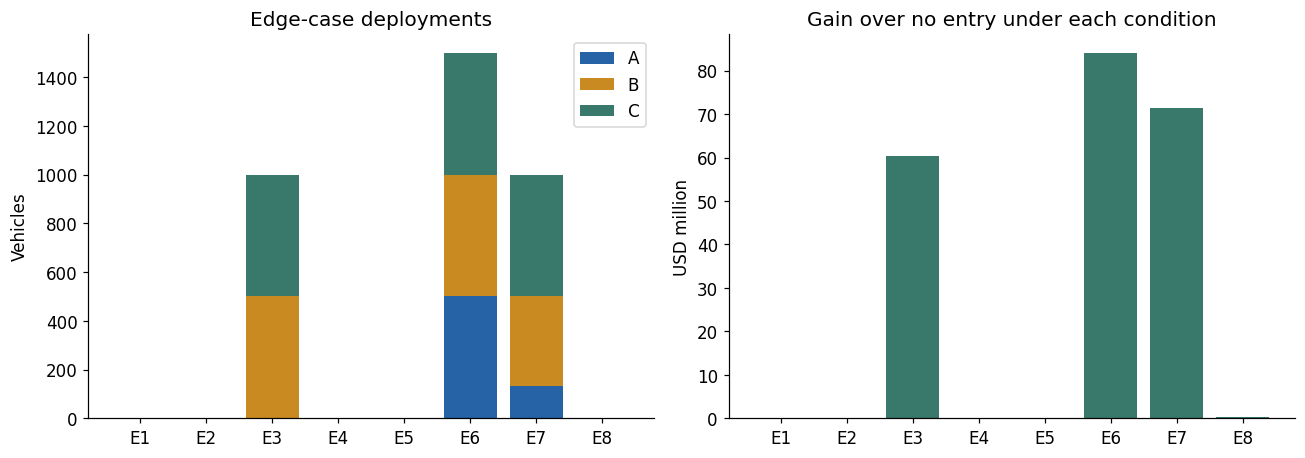

E8에서 F를 그대로 350만 USD로 두면 한 대의 서비스 가치가 진입비를 회수하지 못해 미진입이 정상이다. 따라서 수요·용량 일치 검사는 F=0으로 명시적으로 바꾸었다. 이 변경을 숨기고 작은 사례의 예상값을 그대로 적용하지 않는다.

In [ ]:
edge_specs=[
 ('E1','가용 차량 없음',{'Q':0},'모든 q=0, U=D, Z=Z0'),
 ('E2','수요 없음',{'M':np.zeros(3)},'미진입, Z=0, O=U=0'),
 ('E3','A 배치 금지',{'qbar':np.array([0,500,500])},'A=0; B,C 배치는 국소 최적 (한 대 증감으로 개선 불가)'),
 ('E4','미충족 손실 없음',{'c_minus':np.zeros(3)},'미진입, Z=0'),
 ('E5','매우 큰 진입비',{'F':np.full(3,b['no_entry']+1)},'진입비가 전체 서비스 가치보다 커 미진입'),
 ('E6','총차량 한도 완화',{'Q':2000},'Q 비구속: 총 ≤ 1,500대, 개선액 ≥ 기본, 국소 최적'),
 ('E7','진입비 없음',{'F':np.zeros(3)},'개선액 ≥ 기본; 총 ≤ Q'),
 ('E8','수요=차량 한 대 용량',{'p':np.tile(BASE['kappa']/BASE['M'],(3,1)),'F':np.zeros(3)},
  'F도 0으로 바꿔 진입을 가능하게 함; 도시별 1대, O=U=0')]
def locally_optimal(d,r):
    # 대표해에서 한 도시의 차량을 한 대 늘리거나 줄여도(진입 여부 포함) 개선액이 늘지 않는지 확인
    qq=np.array(r['q']);best=r['gain']
    for cc in range(3):
        for step in (-1,1):
            q2=qq.copy();q2[cc]+=step
            if q2[cc]<0 or q2[cc]>d['qbar'][cc] or q2.sum()>d['Q']:continue
            if evaluate(d,q2)['gain']>best+TOL_USD:return False
    return True
edge_answers={};edge_rows=[]
for case,title,changes,expected in edge_specs:
    d=deepcopy(BASE);d.update(deepcopy(changes));a=solve(d,case);r=a['rep'];o=a['oracle']
    if case in ['E1','E2','E4','E5']:ok=np.all(o['q_max']==0)
    elif case=='E3':ok=o['q_min'][0]==0 and o['q_max'][0]==0 and locally_optimal(d,r)
    elif case=='E6':ok=sum(r['q'])<=int(d['qbar'].sum()) and r['gain']>=b['gain']-TOL_USD and locally_optimal(d,r)
    elif case=='E7':ok=r['gain']>=b['gain']-TOL_USD and sum(r['q'])<=d['Q']
    else:ok=np.array_equal(o['q_min'],[1,1,1]) and np.array_equal(o['q_max'],[1,1,1]) and r['unused']==0 and r['unmet']==0
    if case=='E1':ok=ok and abs(r['cost']-r['no_entry'])<TOL_USD
    if case in ['E2','E4']:ok=ok and abs(r['cost'])<TOL_USD
    assert ok,(case,r)
    edge_answers[case]=a
    edge_rows.append({'검사':case,'조건':title,'변경 입력':str(changes),'예상 성질':expected,'검사 결과':'PASS',**report_row(a)})
edge_table=pd.DataFrame(edge_rows)
show('엣지 케이스: 변경 조건과 검사',edge_table[['검사','조건','변경 입력','예상 성질','검사 결과']])
show('엣지 케이스: 배치와 서비스',edge_table[['검사','대표 배치','최적 q 개수','처리율 (%)','평균 처리량','평균 미충족','평균 유휴']])
show('엣지 케이스: 비용 분해 (USD)',edge_table[['검사','진입비','차량비','유휴 페널티','미충족 손실','목적함수','미진입 기준','개선액']])
fig,axes=plt.subplots(1,2,figsize=(12,4.3));bottom=np.zeros(8)
for cc in range(3):
    vals=[a['rep']['q'][cc] for a in edge_answers.values()]
    axes[0].bar(list(edge_answers),vals,bottom=bottom,color=COLORS[cc],label=cities[cc]);bottom+=vals
axes[0].legend();axes[0].set_ylabel(L('대','Vehicles'));axes[0].set_title(L('엣지 케이스 대표 배치','Edge-case deployments'))
axes[1].bar(list(edge_answers),[a['rep']['gain']/1e6 for a in edge_answers.values()],color='#39796b')
axes[1].set_ylabel('USD million');axes[1].set_title(L('각 조건의 미진입 대비 개선','Gain over no entry under each condition'))
showfig(fig,'03_edges')
note('E8에서 F를 그대로 350만 USD로 두면 한 대의 서비스 가치가 진입비를 회수하지 못해 미진입이 정상이다. '
     '따라서 수요·용량 일치 검사는 F=0으로 명시적으로 바꾸었다. 이 변경을 숨기고 작은 사례의 예상값을 그대로 적용하지 않는다.')


## 3. 민감도 분석
### 3-1. 공통 입력 변화
문서의 비교값을 포함하면서 변화가 보이도록 중간점도 계산한다. 한 번에 한 입력만 바꾼다.
아래 F,K,kappa,c+,c-,qbar 변경은 **모든 도시에 동시에** 적용한다.
M 배율은 세 도시의 M을 같은 비율로 바꾼다(도시 간 비율 0.75 : 1 : 1.25 유지). p 배율은 무작위로 정한 p 행렬 전체에 곱한다.
별도의 M_A와 도시별 분석에서는 한 도시만 변경한다.
그래프의 배치는 대표해이며 음영은 모든 최적 q의 도시별 범위이다. 비용·처리율은 대표해 기준이다.
입력이 다르면 목적함수의 의미도 달라질 수 있으므로 처리량·처리율·개선액을 함께 읽는다.


In [ ]:
experiments={};sensitivity_tables={}
def run_sweep(name,values,change):
    results=[]
    for value in values:
        d=deepcopy(BASE);change(d,float(value));a=solve(d,f'{name}={value:g}');results.append((float(value),a))
    experiments[name]=results
    table=pd.DataFrame([{'입력값':v,**report_row(a)} for v,a in results])
    table['기준 대비 처리량 변화']=table['평균 처리량']-b['served']
    table['기준 대비 처리율 변화 (%p)']=table['처리율 (%)']-100*b['service_rate']
    table['기준 대비 목적함수 변화']=table['목적함수']-b['cost']
    table['기준 대비 개선액 변화']=table['개선액']-b['gain']
    sensitivity_tables[name]=table;return results

def plot_sweep(name,results,xlabel,divisor=1):
    xx=np.array([v for v,a in results])/divisor;rr=[a['rep'] for v,a in results]
    fig,axes=plt.subplots(2,2,figsize=(13,8))
    for c in range(3):
        axes[0,0].plot(xx,[r['q'][c] for r in rr],color=COLORS[c],marker=['o','s','^'][c],linestyle=['-','--',':'][c],label=cities[c])
        axes[0,0].fill_between(xx,[a['oracle']['q_min'][c] for v,a in results],[a['oracle']['q_max'][c] for v,a in results],color=COLORS[c],alpha=.09)
    axes[0,0].legend(ncols=3);axes[0,0].set_ylim(bottom=0);axes[0,0].set_ylabel(L('대','Vehicles'))
    axes[0,0].set_title(L('① 대표 배치와 모든 최적해 범위','1. Representative deployment and ranges over ties'))
    axes[0,1].plot(xx,[100*r['service_rate'] for r in rr],marker='o',color='#2563a6')
    axes[0,1].set_ylim(bottom=0);axes[0,1].set_ylabel('%');axes[0,1].set_title(L('② 전체 수요 처리율','2. Share of total demand served'))
    compnames=[L('진입비','Entry'),L('차량비','Vehicle'),L('유휴 페널티','Idle'),L('미충족 손실','Unmet')]
    for j in range(4):axes[1,0].plot(xx,[r['components'][j]/1e6 for r in rr],linestyle=['-','--',':','-.'][j],label=compnames[j])
    axes[1,0].plot(xx,[r['cost']/1e6 for r in rr],color='black',label=L('합계','Total'))
    axes[1,0].set_ylim(bottom=0);axes[1,0].legend(ncols=2,fontsize=9);axes[1,0].set_ylabel('USD million')
    axes[1,0].set_title(L('③ 목적함수와 비용 분해','3. Objective and components'))
    axes[1,1].plot(xx,[r['gain']/1e6 for r in rr],marker='o',color='#39796b');axes[1,1].set_ylim(bottom=0)
    axes[1,1].set_ylabel('USD million');axes[1,1].set_title(L('④ 같은 조건의 미진입 대비 개선','4. Gain over no entry in the same setting'))
    for ax in axes.flat:ax.set_xlabel(xlabel);ax.grid(alpha=.15)
    fig.suptitle(name);fig.subplots_adjust(top=.92)
    showfig(fig,'sweep_'+name.replace(' ','_').replace('+','plus'))
    t=sensitivity_tables[name]
    show(name+' 주요 비교',t[['입력값','대표 배치','최적 q 개수','처리율 (%)','평균 유휴','목적함수','개선액']].round(4))
    detail('전체 수치: 처리량·비용 분해·기준 대비 변화',t)
    changed=[]
    for (v0,a0),(v1,a1) in zip(results,results[1:]):
        signature=lambda a:(a['oracle']['count'],tuple(a['oracle']['q_min']),tuple(a['oracle']['q_max']),a['oracle']['q'])
        if signature(a0)!=signature(a1):changed.append(f'{v0:g} → {v1:g}')
    note('**배치 집합 변화가 관찰된 실행 구간:** '+(', '.join(changed) if changed else '조사 범위에서 배치 집합 요약이 동일함')+
         '. 인접 실행점 사이를 더 계산하지 않으면 정확한 전환점이라고 단정하지 않는다.')

sweep_specs=[
 ('Q',sorted(set(range(0,2001,100))),lambda d,v:d.update(Q=int(v)),L('총차량 한도 (대)','Fleet limit'),1),
 ('F',F[0]*np.linspace(.75,1.25,9),lambda d,v:d.update(F=np.full(3,v)),L('도시당 진입비 (백만 USD)','Entry cost (USD million)'),1e6),
 ('K',K[0]*np.linspace(.75,1.25,9),lambda d,v:d.update(K=np.full(3,v)),L('차량비 (USD/대·년)','Vehicle cost (USD/vehicle-year)'),1),
 ('kappa',kappa[0]*np.linspace(.75,1.25,9),lambda d,v:d.update(kappa=np.full(3,v)),L('건/대·년','Trips/vehicle-year'),1),
 ('M_multiplier',np.linspace(.75,1.25,9),lambda d,v:d.update(M=BASE['M']*v),L('모든 도시 M 배율 (도시 간 비율 유지)','Multiplier on all M (ratios kept)'),1),
 ('qbar',[100,250,500,750,1000,1500],lambda d,v:d.update(qbar=np.full(3,int(v))),L('도시당 차량 상한','City vehicle cap'),1),
 ('c_plus',[0,1,3,5,10,15,40],lambda d,v:d.update(c_plus=np.full(3,v)),L('USD/유휴 용량 1건','USD/unused trip capacity'),1),
 ('c_minus',[2,5,10,15,20],lambda d,v:d.update(c_minus=np.full(3,v)),L('USD/미충족 1건','USD/unserved trip'),1),
 ('p_multiplier',[.75,1,1.25],lambda d,v:d.update(p=BASE['p']*v),L('모든 도시 p의 배율','Multiplier on all choice probabilities'),1),
 ('M_A_multiplier',np.linspace(.75,1.25,9),lambda d,v:d['M'].__setitem__(0,BASE['M'][0]*v),L('A의 M 배율','Multiplier on A market size'),1),
 ('alpha',np.linspace(0,1,11),lambda d,v:d.update(p=BASE['p'].mean(axis=0)+v*(BASE['p']-BASE['p'].mean(axis=0))),L('평균 유지 수요 변동 배율','Mean-preserving demand spread'),1)]
show('변경 범위 (표시하지 않은 입력은 기본값)',pd.DataFrame([{
    '입력':name,'최솟값':float(min(vals)),'최댓값':float(max(vals)),'설정 수':len(vals),
    '변경 대상':'A만' if name=='M_A_multiplier' else ('전체 한도' if name=='Q' else '모든 도시'),
    '출처 범위':'추가 설계: p 배율/변동성' if name in ['p_multiplier','alpha'] else ('문서 0,1,3,5 + 추가 10,15,20' if name=='c_plus' else ('문서 ±25% 범위를 도시별 M에 배율로 적용' if name=='M_multiplier' else '문서 비교값 포함'))}
    for name,vals,change,xlabel,divisor in sweep_specs]))

**변경 범위 (표시하지 않은 입력은 기본값)**

,입력,최솟값,최댓값,설정 수,변경 대상,출처 범위
0,Q,0.00,2000.00,21,전체 한도,문서 비교값 포함
1,F,2625000.00,4375000.00,9,모든 도시,문서 비교값 포함
2,K,5979.00,9965.00,9,모든 도시,문서 비교값 포함
3,kappa,6570.00,10950.00,9,모든 도시,문서 비교값 포함
4,M_multiplier,0.75,1.25,9,모든 도시,문서 ±25% 범위를 도시별 M에 배율로 적용
5,qbar,100.00,1500.00,6,모든 도시,문서 비교값 포함
6,c_plus,0.00,40.00,7,모든 도시,"문서 0,1,3,5 + 추가 10,15,20"
7,c_minus,2.00,20.00,5,모든 도시,문서 비교값 포함
8,p_multiplier,0.75,1.25,3,모든 도시,추가 설계: p 배율/변동성
9,M_A_multiplier,0.75,1.25,9,A만,문서 비교값 포함


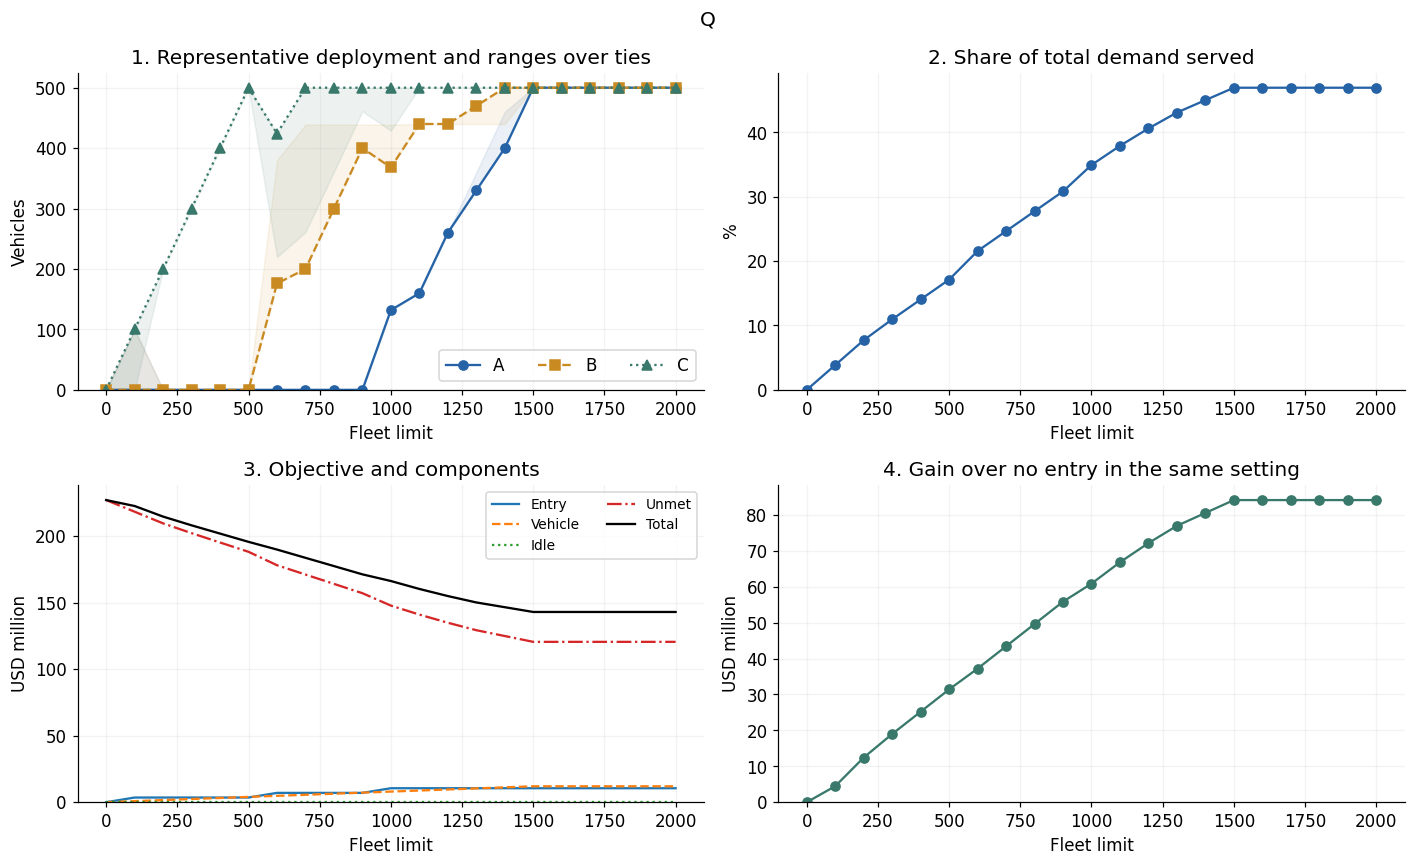

**Q 주요 비교**

,입력값,대표 배치,최적 q 개수,처리율 (%),평균 유휴,목적함수,개선액
0,0.0,"(0, 0, 0)",1,0.0000,0.000,2.271179e+08,0.00
1,100.0,"(0, 0, 100)",3,3.8570,0.000,2.226551e+08,4462800.00
2,200.0,"(0, 0, 200)",1,7.7141,0.000,2.146923e+08,12425600.00
3,300.0,"(0, 0, 300)",1,10.9532,140327.930,2.081328e+08,18985120.70
4,400.0,"(0, 0, 400)",1,14.0388,315527.930,2.019220e+08,25195920.70
5,500.0,"(0, 0, 500)",1,17.1245,490727.930,1.957112e+08,31406720.70
6,600.0,"(0, 176, 424)",205,21.5672,357710.274,1.899182e+08,37199697.26
7,700.0,"(0, 200, 500)",240,24.6528,532910.274,1.837074e+08,43410497.26
8,800.0,"(0, 300, 500)",140,27.7384,708110.274,1.774966e+08,49621297.26
9,900.0,"(0, 400, 500)",40,30.8240,883310.274,1.712858e+08,55832097.26


입력값,대표 배치,최적 q 개수,평균 수요,평균 처리량,평균 미충족,평균 유휴,처리율 (%),활용률 (%),진입비,차량비,유휴 페널티,미충족 손실,목적함수,미진입 기준,개선액,모든 최적 q의 도시별 최소,모든 최적 q의 도시별 최대,기준 대비 처리량 변화,기준 대비 처리율 변화 (%p),기준 대비 목적함수 변화,기준 대비 개선액 변화
0.0000,"(0, 0, 0)",1,"22,711,788.5265",0.0000,"22,711,788.5265",0.0000,0.0000,NaN,0.0000,0.0000,0.0000,"227,117,885.2650","227,117,885.2650","227,117,885.2650",0.0000,"(0, 0, 0)","(0, 0, 0)","-7,932,602.5890",-34.9272,"60,854,025.8900","-60,854,025.8900"
100.0000,"(0, 0, 100)",3,"22,711,788.5265","876,000.0000","21,835,788.5265",0.0000,3.8570,100.0000,"3,500,000.0000","797,200.0000",0.0000,"218,357,885.2650","222,655,085.2650","227,117,885.2650","4,462,800.0000","(0, 0, 0)","(100, 100, 100)","-7,056,602.5890",-31.0702,"56,391,225.8900","-56,391,225.8900"
200.0000,"(0, 0, 200)",1,"22,711,788.5265","1,752,000.0000","20,959,788.5265",0.0000,7.7141,100.0000,"3,500,000.0000","1,594,400.0000",0.0000,"209,597,885.2650","214,692,285.2650","227,117,885.2650","12,425,600.0000","(0, 0, 200)","(0, 0, 200)","-6,180,602.5890",-27.2132,"48,428,425.8900","-48,428,425.8900"
300.0000,"(0, 0, 300)",1,"22,711,788.5265","2,487,672.0700","20,224,116.4565","140,327.9300",10.9532,94.6603,"3,500,000.0000","2,391,600.0000",0.0000,"202,241,164.5650","208,132,764.5650","227,117,885.2650","18,985,120.7000","(0, 0, 300)","(0, 0, 300)","-5,444,930.5190",-23.9740,"41,868,905.1900","-41,868,905.1900"
400.0000,"(0, 0, 400)",1,"22,711,788.5265","3,188,472.0700","19,523,316.4565","315,527.9300",14.0388,90.9952,"3,500,000.0000","3,188,800.0000",0.0000,"195,233,164.5650","201,921,964.5650","227,117,885.2650","25,195,920.7000","(0, 0, 400)","(0, 0, 400)","-4,744,130.5190",-20.8884,"35,658,105.1900","-35,658,105.1900"
500.0000,"(0, 0, 500)",1,"22,711,788.5265","3,889,272.0700","18,822,516.4565","490,727.9300",17.1245,88.7962,"3,500,000.0000","3,986,000.0000",0.0000,"188,225,164.5650","195,711,164.5650","227,117,885.2650","31,406,720.7000","(0, 0, 500)","(0, 0, 500)","-4,043,330.5190",-17.8028,"29,447,305.1900","-29,447,305.1900"
600.0000,"(0, 176, 424)",205,"22,711,788.5265","4,898,289.7260","17,813,498.8005","357,710.2740",21.5672,93.1942,"7,000,000.0000","4,783,200.0000",0.0000,"178,134,988.0050","189,918,188.0050","227,117,885.2650","37,199,697.2600","(0, 176, 220)","(0, 380, 424)","-3,034,312.8630",-13.3601,"23,654,328.6300","-23,654,328.6300"
700.0000,"(0, 200, 500)",240,"22,711,788.5265","5,599,089.7260","17,112,698.8005","532,910.2740",24.6528,91.3094,"7,000,000.0000","5,580,400.0000",0.0000,"171,126,988.0050","183,707,388.0050","227,117,885.2650","43,410,497.2600","(0, 200, 261)","(0, 439, 500)","-2,333,512.8630",-10.2745,"17,443,528.6300","-17,443,528.6300"
800.0000,"(0, 300, 500)",140,"22,711,788.5265","6,299,889.7260","16,411,898.8005","708,110.2740",27.7384,89.8957,"7,000,000.0000","6,377,600.0000",0.0000,"164,118,988.0050","177,496,588.0050","227,117,885.2650","49,621,297.2600","(0, 300, 361)","(0, 439, 500)","-1,632,712.8630",-7.1888,"11,232,728.6300","-11,232,728.6300"
900.0000,"(0, 400, 500)",40,"22,711,788.5265","7,000,689.7260","15,711,098.8005","883,310.2740",30.8240,88.7962,"7,000,000.0000","7,174,800.0000",0.0000,"157,110,988.0050","171,285,788.0050","227,117,885.2650","55,832,097.2600","(0, 400, 461)","(0, 439, 500)","-931,912.8630",-4.1032,"5,021,928.6300","-5,021,928.6300"


**배치 집합 변화가 관찰된 실행 구간:** 0 → 100, 100 → 200, 200 → 300, 300 → 400, 400 → 500, 500 → 600, 600 → 700, 700 → 800, 800 → 900, 900 → 1000, 1000 → 1100, 1100 → 1200, 1200 → 1300, 1300 → 1400, 1400 → 1500. 인접 실행점 사이를 더 계산하지 않으면 정확한 전환점이라고 단정하지 않는다.

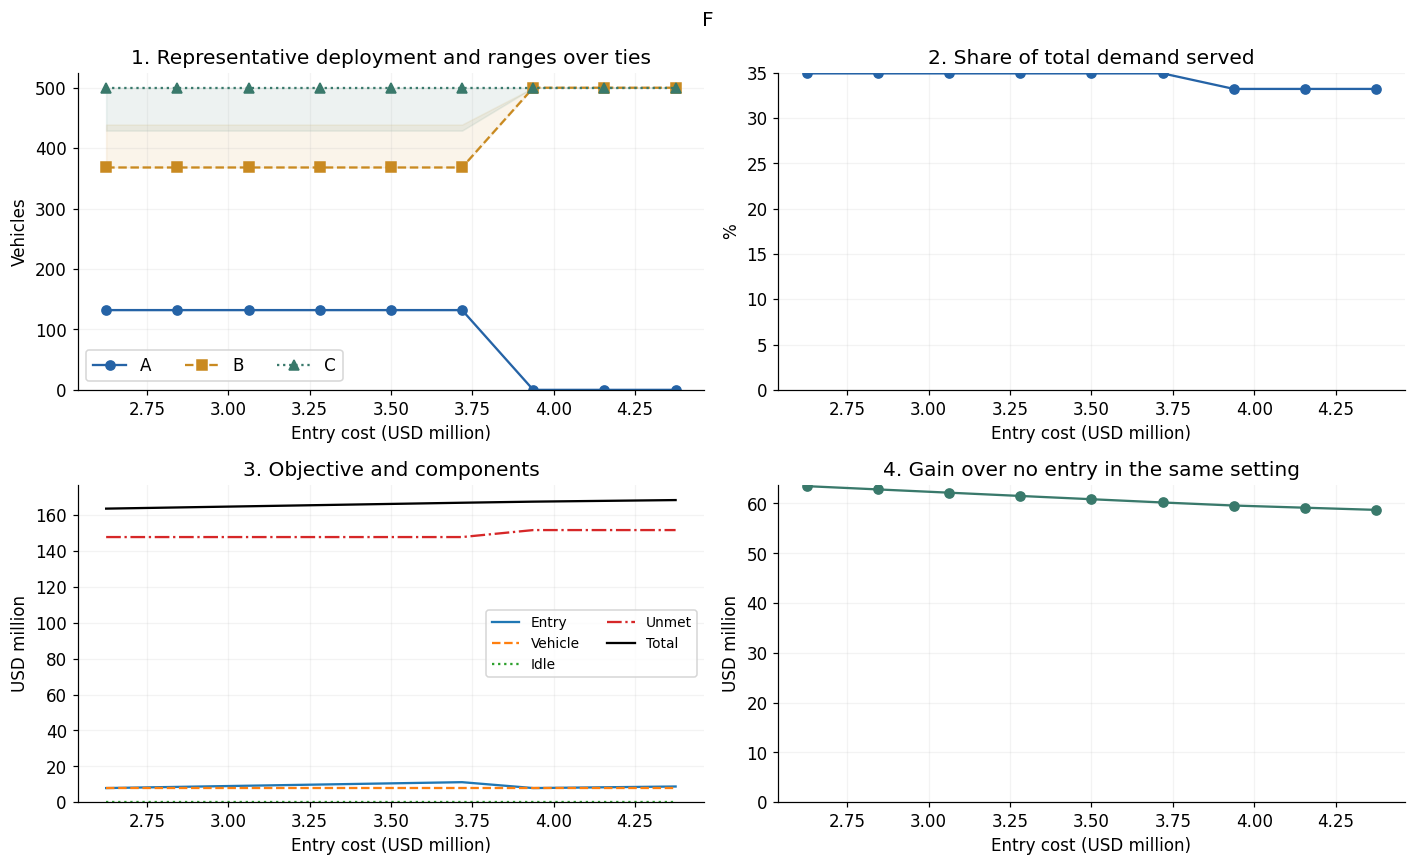

**F 주요 비교**

,입력값,대표 배치,최적 q 개수,처리율 (%),평균 유휴,목적함수,개선액
0,2625000.0,"(132, 368, 500)",72,34.9272,827397.411,1.636389e+08,63479025.89
1,2843750.0,"(132, 368, 500)",72,34.9272,827397.411,1.642951e+08,62822775.89
2,3062500.0,"(132, 368, 500)",72,34.9272,827397.411,1.649514e+08,62166525.89
3,3281250.0,"(132, 368, 500)",72,34.9272,827397.411,1.656076e+08,61510275.89
4,3500000.0,"(132, 368, 500)",72,34.9272,827397.411,1.662639e+08,60854025.89
5,3718750.0,"(132, 368, 500)",72,34.9272,827397.411,1.669201e+08,60197775.89
6,3937500.0,"(0, 500, 500)",1,33.2132,1216694.064,1.675318e+08,59586059.36
7,4156250.0,"(0, 500, 500)",1,33.2132,1216694.064,1.679693e+08,59148559.36
8,4375000.0,"(0, 500, 500)",1,33.2132,1216694.064,1.684068e+08,58711059.36


입력값,대표 배치,최적 q 개수,평균 수요,평균 처리량,평균 미충족,평균 유휴,처리율 (%),활용률 (%),진입비,차량비,유휴 페널티,미충족 손실,목적함수,미진입 기준,개선액,모든 최적 q의 도시별 최소,모든 최적 q의 도시별 최대,기준 대비 처리량 변화,기준 대비 처리율 변화 (%p),기준 대비 목적함수 변화,기준 대비 개선액 변화
"2,625,000.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"7,875,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","163,638,859.3750","227,117,885.2650","63,479,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"-2,625,000.0000","2,625,000.0000"
"2,843,750.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"8,531,250.0000","7,972,000.0000",0.0000,"147,791,859.3750","164,295,109.3750","227,117,885.2650","62,822,775.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"-1,968,750.0000","1,968,750.0000"
"3,062,500.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"9,187,500.0000","7,972,000.0000",0.0000,"147,791,859.3750","164,951,359.3750","227,117,885.2650","62,166,525.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"-1,312,500.0000","1,312,500.0000"
"3,281,250.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"9,843,750.0000","7,972,000.0000",0.0000,"147,791,859.3750","165,607,609.3750","227,117,885.2650","61,510,275.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"-656,250.0000","656,250.0000"
"3,500,000.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
"3,718,750.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"11,156,250.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,920,109.3750","227,117,885.2650","60,197,775.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"656,250.0000","-656,250.0000"
"3,937,500.0000","(0, 500, 500)",1,"22,711,788.5265","7,543,305.9360","15,168,482.5905","1,216,694.0640",33.2132,86.1108,"7,875,000.0000","7,972,000.0000",0.0000,"151,684,825.9050","167,531,825.9050","227,117,885.2650","59,586,059.3600","(0, 500, 500)","(0, 500, 500)","-389,296.6530",-1.7141,"1,267,966.5300","-1,267,966.5300"
"4,156,250.0000","(0, 500, 500)",1,"22,711,788.5265","7,543,305.9360","15,168,482.5905","1,216,694.0640",33.2132,86.1108,"8,312,500.0000","7,972,000.0000",0.0000,"151,684,825.9050","167,969,325.9050","227,117,885.2650","59,148,559.3600","(0, 500, 500)","(0, 500, 500)","-389,296.6530",-1.7141,"1,705,466.5300","-1,705,466.5300"
"4,375,000.0000","(0, 500, 500)",1,"22,711,788.5265","7,543,305.9360","15,168,482.5905","1,216,694.0640",33.2132,86.1108,"8,750,000.0000","7,972,000.0000",0.0000,"151,684,825.9050","168,406,825.9050","227,117,885.2650","58,711,059.3600","(0, 500, 500)","(0, 500, 500)","-389,296.6530",-1.7141,"2,142,966.5300","-2,142,966.5300"


**배치 집합 변화가 관찰된 실행 구간:** 3.71875e+06 → 3.9375e+06. 인접 실행점 사이를 더 계산하지 않으면 정확한 전환점이라고 단정하지 않는다.

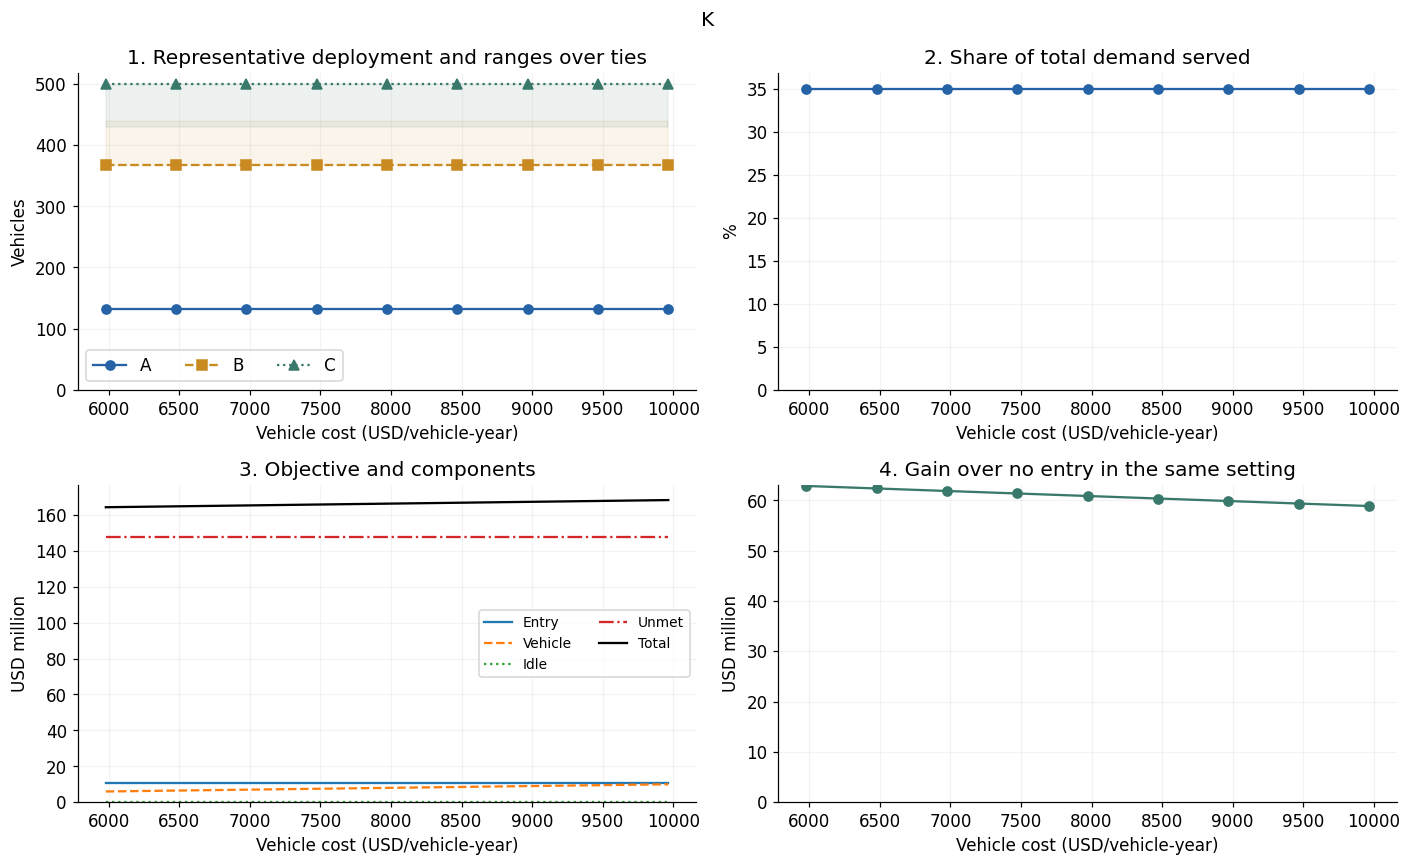

**K 주요 비교**

,입력값,대표 배치,최적 q 개수,처리율 (%),평균 유휴,목적함수,개선액
0,5979.00,"(132, 368, 500)",72,34.9272,827397.411,1.642709e+08,62847025.89
1,6477.25,"(132, 368, 500)",72,34.9272,827397.411,1.647691e+08,62348775.89
2,6975.50,"(132, 368, 500)",72,34.9272,827397.411,1.652674e+08,61850525.89
3,7473.75,"(132, 368, 500)",72,34.9272,827397.411,1.657656e+08,61352275.89
4,7972.00,"(132, 368, 500)",72,34.9272,827397.411,1.662639e+08,60854025.89
5,8470.25,"(132, 368, 500)",72,34.9272,827397.411,1.667621e+08,60355775.89
6,8968.50,"(132, 368, 500)",72,34.9272,827397.411,1.672604e+08,59857525.89
7,9466.75,"(132, 368, 500)",72,34.9272,827397.411,1.677586e+08,59359275.89
8,9965.00,"(132, 368, 500)",72,34.9272,827397.411,1.682569e+08,58861025.89


입력값,대표 배치,최적 q 개수,평균 수요,평균 처리량,평균 미충족,평균 유휴,처리율 (%),활용률 (%),진입비,차량비,유휴 페널티,미충족 손실,목적함수,미진입 기준,개선액,모든 최적 q의 도시별 최소,모든 최적 q의 도시별 최대,기준 대비 처리량 변화,기준 대비 처리율 변화 (%p),기준 대비 목적함수 변화,기준 대비 개선액 변화
"5,979.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","5,979,000.0000",0.0000,"147,791,859.3750","164,270,859.3750","227,117,885.2650","62,847,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"-1,993,000.0000","1,993,000.0000"
"6,477.2500","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","6,477,250.0000",0.0000,"147,791,859.3750","164,769,109.3750","227,117,885.2650","62,348,775.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"-1,494,750.0000","1,494,750.0000"
"6,975.5000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","6,975,500.0000",0.0000,"147,791,859.3750","165,267,359.3750","227,117,885.2650","61,850,525.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"-996,500.0000","996,500.0000"
"7,473.7500","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,473,750.0000",0.0000,"147,791,859.3750","165,765,609.3750","227,117,885.2650","61,352,275.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"-498,250.0000","498,250.0000"
"7,972.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
"8,470.2500","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","8,470,250.0000",0.0000,"147,791,859.3750","166,762,109.3750","227,117,885.2650","60,355,775.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"498,250.0000","-498,250.0000"
"8,968.5000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","8,968,500.0000",0.0000,"147,791,859.3750","167,260,359.3750","227,117,885.2650","59,857,525.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"996,500.0000","-996,500.0000"
"9,466.7500","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","9,466,750.0000",0.0000,"147,791,859.3750","167,758,609.3750","227,117,885.2650","59,359,275.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"1,494,750.0000","-1,494,750.0000"
"9,965.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","9,965,000.0000",0.0000,"147,791,859.3750","168,256,859.3750","227,117,885.2650","58,861,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"1,993,000.0000","-1,993,000.0000"


**배치 집합 변화가 관찰된 실행 구간:** 조사 범위에서 배치 집합 요약이 동일함. 인접 실행점 사이를 더 계산하지 않으면 정확한 전환점이라고 단정하지 않는다.

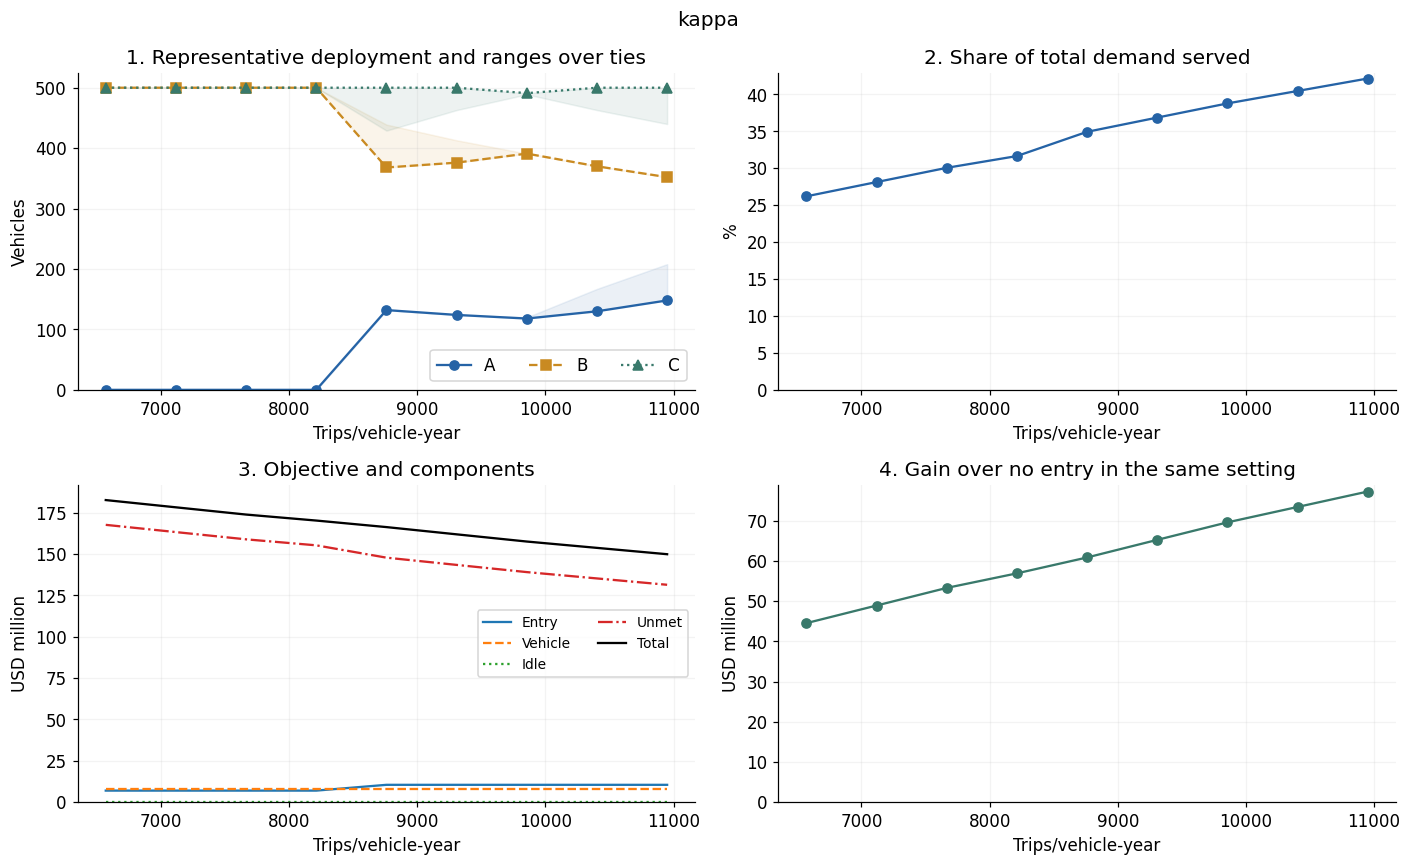

**kappa 주요 비교**

,입력값,대표 배치,최적 q 개수,처리율 (%),평균 유휴,목적함수,개선액
0,6570.0,"(0, 500, 500)",1,26.1956,6.205103e+05,1.825950e+08,4.452290e+07
1,7117.5,"(0, 500, 500)",1,28.1241,7.300103e+05,1.782150e+08,4.890290e+07
2,7665.0,"(0, 500, 500)",1,30.0526,8.395103e+05,1.738350e+08,5.328290e+07
3,8212.5,"(0, 500, 500)",1,31.6463,1.025069e+06,1.702156e+08,5.690231e+07
4,8760.0,"(132, 368, 500)",72,34.9272,8.273974e+05,1.662639e+08,6.085403e+07
5,9307.5,"(124, 376, 500)",38,36.8545,9.371843e+05,1.618867e+08,6.523116e+07
6,9855.0,"(118, 391, 491)",3,38.7705,1.049520e+06,1.575351e+08,6.958280e+07
7,10402.5,"(130, 370, 500)",38,40.4568,1.214033e+06,1.537052e+08,7.341267e+07
8,10950.0,"(148, 352, 500)",61,42.1445,1.378239e+06,1.498723e+08,7.724561e+07


입력값,대표 배치,최적 q 개수,평균 수요,평균 처리량,평균 미충족,평균 유휴,처리율 (%),활용률 (%),진입비,차량비,유휴 페널티,미충족 손실,목적함수,미진입 기준,개선액,모든 최적 q의 도시별 최소,모든 최적 q의 도시별 최대,기준 대비 처리량 변화,기준 대비 처리율 변화 (%p),기준 대비 목적함수 변화,기준 대비 개선액 변화
"6,570.0000","(0, 500, 500)",1,"22,711,788.5265","5,949,489.7260","16,762,298.8005","620,510.2740",26.1956,90.5554,"7,000,000.0000","7,972,000.0000",0.0000,"167,622,988.0050","182,594,988.0050","227,117,885.2650","44,522,897.2600","(0, 500, 500)","(0, 500, 500)","-1,983,112.8630",-8.7316,"16,331,128.6300","-16,331,128.6300"
"7,117.5000","(0, 500, 500)",1,"22,711,788.5265","6,387,489.7260","16,324,298.8005","730,010.2740",28.1241,89.7434,"7,000,000.0000","7,972,000.0000",0.0000,"163,242,988.0050","178,214,988.0050","227,117,885.2650","48,902,897.2600","(0, 500, 500)","(0, 500, 500)","-1,545,112.8630",-6.8031,"11,951,128.6300","-11,951,128.6300"
"7,665.0000","(0, 500, 500)",1,"22,711,788.5265","6,825,489.7260","15,886,298.8005","839,510.2740",30.0526,89.0475,"7,000,000.0000","7,972,000.0000",0.0000,"158,862,988.0050","173,834,988.0050","227,117,885.2650","53,282,897.2600","(0, 500, 500)","(0, 500, 500)","-1,107,112.8630",-4.8746,"7,571,128.6300","-7,571,128.6300"
"8,212.5000","(0, 500, 500)",1,"22,711,788.5265","7,187,430.9360","15,524,357.5905","1,025,069.0640",31.6463,87.5182,"7,000,000.0000","7,972,000.0000",0.0000,"155,243,575.9050","170,215,575.9050","227,117,885.2650","56,902,309.3600","(0, 500, 500)","(0, 500, 500)","-745,171.6530",-3.2810,"3,951,716.5300","-3,951,716.5300"
"8,760.0000","(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
"9,307.5000","(124, 376, 500)",38,"22,711,788.5265","8,370,315.7260","14,341,472.8005","937,184.2740",36.8545,89.9309,"10,500,000.0000","7,972,000.0000",0.0000,"143,414,728.0050","161,886,728.0050","227,117,885.2650","65,231,157.2600","(124, 376, 463)","(124, 413, 500)","437,713.1370",1.9273,"-4,377,131.3700","4,377,131.3700"
"9,855.0000","(118, 391, 491)",3,"22,711,788.5265","8,805,479.8865","13,906,308.6400","1,049,520.1135",38.7705,89.3504,"10,500,000.0000","7,972,000.0000",0.0000,"139,063,086.4000","157,535,086.4000","227,117,885.2650","69,582,798.8650","(118, 391, 489)","(120, 391, 491)","872,877.2975",3.8433,"-8,728,772.9750","8,728,772.9750"
"10,402.5000","(130, 370, 500)",38,"22,711,788.5265","9,188,467.1765","13,523,321.3500","1,214,032.8235",40.4568,88.3294,"10,500,000.0000","7,972,000.0000",0.0000,"135,233,213.5000","153,705,213.5000","227,117,885.2650","73,412,671.7650","(130, 370, 463)","(167, 370, 500)","1,255,864.5875",5.5296,"-12,558,645.8750","12,558,645.8750"
"10,950.0000","(148, 352, 500)",61,"22,711,788.5265","9,571,760.8865","13,140,027.6400","1,378,239.1135",42.1445,87.4133,"10,500,000.0000","7,972,000.0000",0.0000,"131,400,276.4000","149,872,276.4000","227,117,885.2650","77,245,608.8650","(148, 352, 440)","(208, 352, 500)","1,639,158.2975",7.2172,"-16,391,582.9750","16,391,582.9750"


**배치 집합 변화가 관찰된 실행 구간:** 8212.5 → 8760, 8760 → 9307.5, 9307.5 → 9855, 9855 → 10402.5, 10402.5 → 10950. 인접 실행점 사이를 더 계산하지 않으면 정확한 전환점이라고 단정하지 않는다.

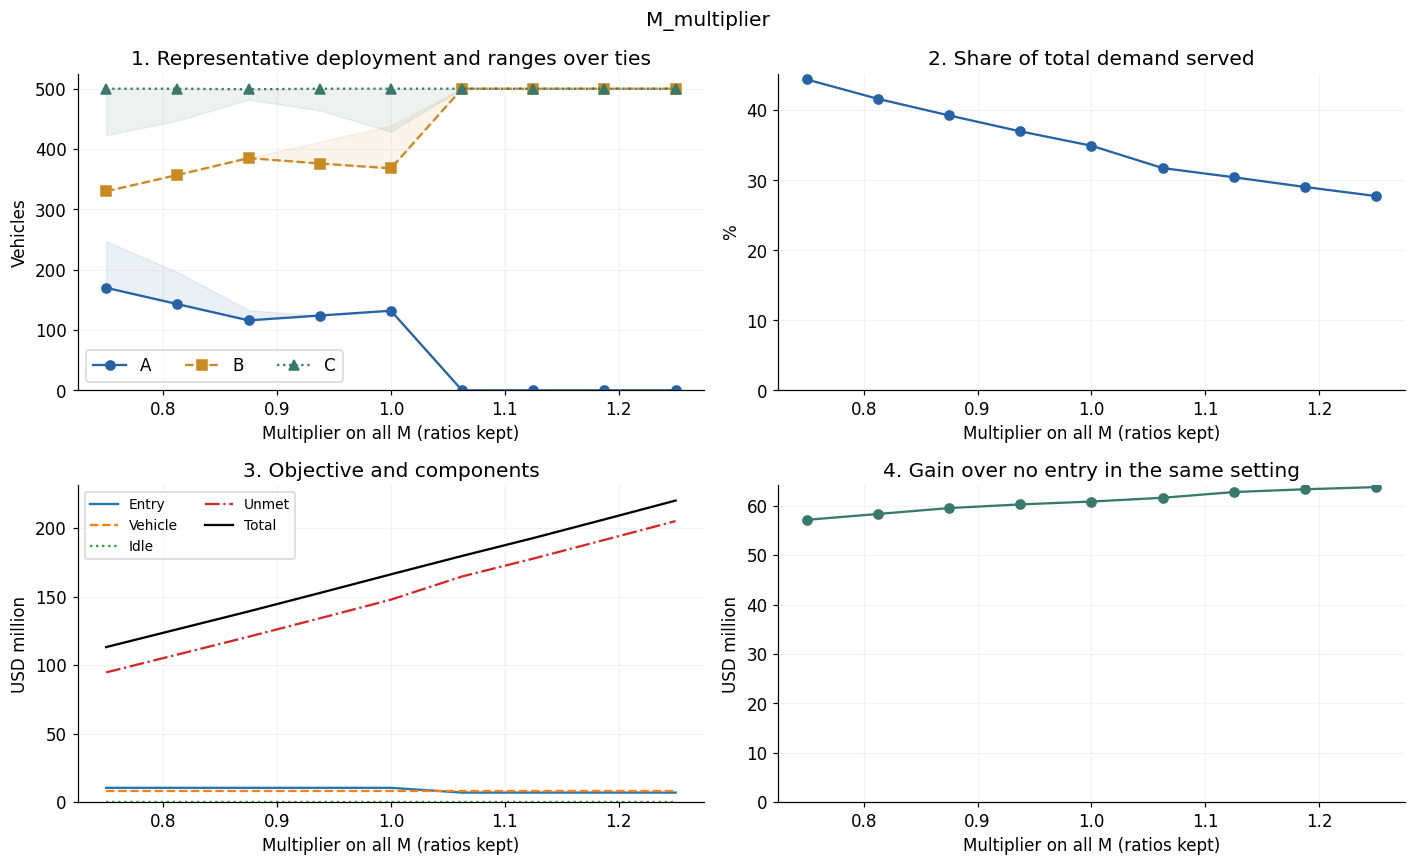

**M_multiplier 주요 비교**

,입력값,대표 배치,최적 q 개수,처리율 (%),평균 유휴,목적함수,개선액
0,0.7500,"(170, 330, 500)",78,44.3944,1.197929e+06,1.131897e+08,5.714871e+07
1,0.8125,"(143, 357, 500)",54,41.6251,1.078785e+06,1.261931e+08,5.834015e+07
2,0.8750,"(116, 385, 499)",18,39.2517,9.595842e+05,1.391960e+08,5.953216e+07
3,0.9375,"(124, 376, 500)",37,36.9833,8.854041e+05,1.526491e+08,6.027396e+07
4,1.0000,"(132, 368, 500)",72,34.9272,8.273974e+05,1.662639e+08,6.085403e+07
5,1.0625,"(0, 500, 500)",1,31.7384,1.101112e+06,1.796959e+08,6.161688e+07
6,1.1250,"(0, 500, 500)",1,30.4275,9.855308e+05,1.927349e+08,6.277269e+07
7,1.1875,"(0, 500, 500)",1,29.0376,9.284810e+05,2.063593e+08,6.334319e+07
8,1.2500,"(0, 500, 500)",1,27.7384,8.851378e+05,2.201207e+08,6.377662e+07


입력값,대표 배치,최적 q 개수,평균 수요,평균 처리량,평균 미충족,평균 유휴,처리율 (%),활용률 (%),진입비,차량비,유휴 페널티,미충족 손실,목적함수,미진입 기준,개선액,모든 최적 q의 도시별 최소,모든 최적 q의 도시별 최대,기준 대비 처리량 변화,기준 대비 처리율 변화 (%p),기준 대비 목적함수 변화,기준 대비 개선액 변화
0.7500,"(170, 330, 500)",78,"17,033,841.3949","7,562,070.6649","9,471,770.7300","1,197,929.3351",44.3944,86.3250,"10,500,000.0000","7,972,000.0000",0.0000,"94,717,707.3000","113,189,707.3000","170,338,413.9487","57,148,706.6487","(170, 330, 423)","(247, 330, 500)","-370,531.9241",9.4671,"-53,074,152.0750","-3,705,319.2412"
0.8125,"(143, 357, 500)",54,"18,453,328.1778","7,681,214.5497","10,772,113.6281","1,078,785.4503",41.6251,87.6851,"10,500,000.0000","7,972,000.0000",0.0000,"107,721,136.2812","126,193,136.2812","184,533,281.7778","58,340,145.4966","(143, 357, 447)","(196, 357, 500)","-251,388.0393",6.6978,"-40,070,723.0938","-2,513,880.3934"
0.8750,"(116, 385, 499)",18,"19,872,814.9607","7,800,415.7757","12,072,399.1850","959,584.2243",39.2517,89.0458,"10,500,000.0000","7,972,000.0000",0.0000,"120,723,991.8500","139,195,991.8500","198,728,149.6069","59,532,157.7569","(116, 385, 482)","(133, 385, 499)","-132,186.8133",4.3244,"-27,067,867.5250","-1,321,868.1331"
0.9375,"(124, 376, 500)",37,"21,292,301.7436","7,874,595.9272","13,417,705.8164","885,404.0728",36.9833,89.8926,"10,500,000.0000","7,972,000.0000",0.0000,"134,177,058.1641","152,649,058.1641","212,923,017.4359","60,273,959.2719","(124, 376, 464)","(124, 412, 500)","-58,006.6618",2.0561,"-13,614,801.2109","-580,066.6181"
1.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
1.0625,"(0, 500, 500)",1,"24,131,275.3094","7,658,887.5570","16,472,387.7524","1,101,112.4430",31.7384,87.4302,"7,000,000.0000","7,972,000.0000",0.0000,"164,723,877.5241","179,695,877.5241","241,312,753.0941","61,616,875.5700","(0, 500, 500)","(0, 500, 500)","-273,715.0320",-3.1888,"13,432,018.1491","762,849.6800"
1.1250,"(0, 500, 500)",1,"25,550,762.0923","7,774,469.1780","17,776,292.9143","985,530.8220",30.4275,88.7496,"7,000,000.0000","7,972,000.0000",0.0000,"177,762,929.1431","192,734,929.1431","255,507,620.9231","62,772,691.7800","(0, 500, 500)","(0, 500, 500)","-158,133.4110",-4.4997,"26,471,069.7681","1,918,665.8900"
1.1875,"(0, 500, 500)",1,"26,970,248.8752","7,831,519.0496","19,138,729.8256","928,480.9504",29.0376,89.4009,"7,000,000.0000","7,972,000.0000",0.0000,"191,387,298.2559","206,359,298.2559","269,702,488.7522","63,343,190.4963","(0, 500, 500)","(0, 500, 500)","-101,083.5394",-5.8896,"40,095,438.8809","2,489,164.6063"
1.2500,"(0, 500, 500)",1,"28,389,735.6581","7,874,862.1575","20,514,873.5006","885,137.8425",27.7384,89.8957,"7,000,000.0000","7,972,000.0000",0.0000,"205,148,735.0062","220,120,735.0062","283,897,356.5813","63,776,621.5750","(0, 500, 500)","(0, 500, 500)","-57,740.4315",-7.1888,"53,856,875.6312","2,922,595.6850"


**배치 집합 변화가 관찰된 실행 구간:** 0.75 → 0.8125, 0.8125 → 0.875, 0.875 → 0.9375, 0.9375 → 1, 1 → 1.0625. 인접 실행점 사이를 더 계산하지 않으면 정확한 전환점이라고 단정하지 않는다.

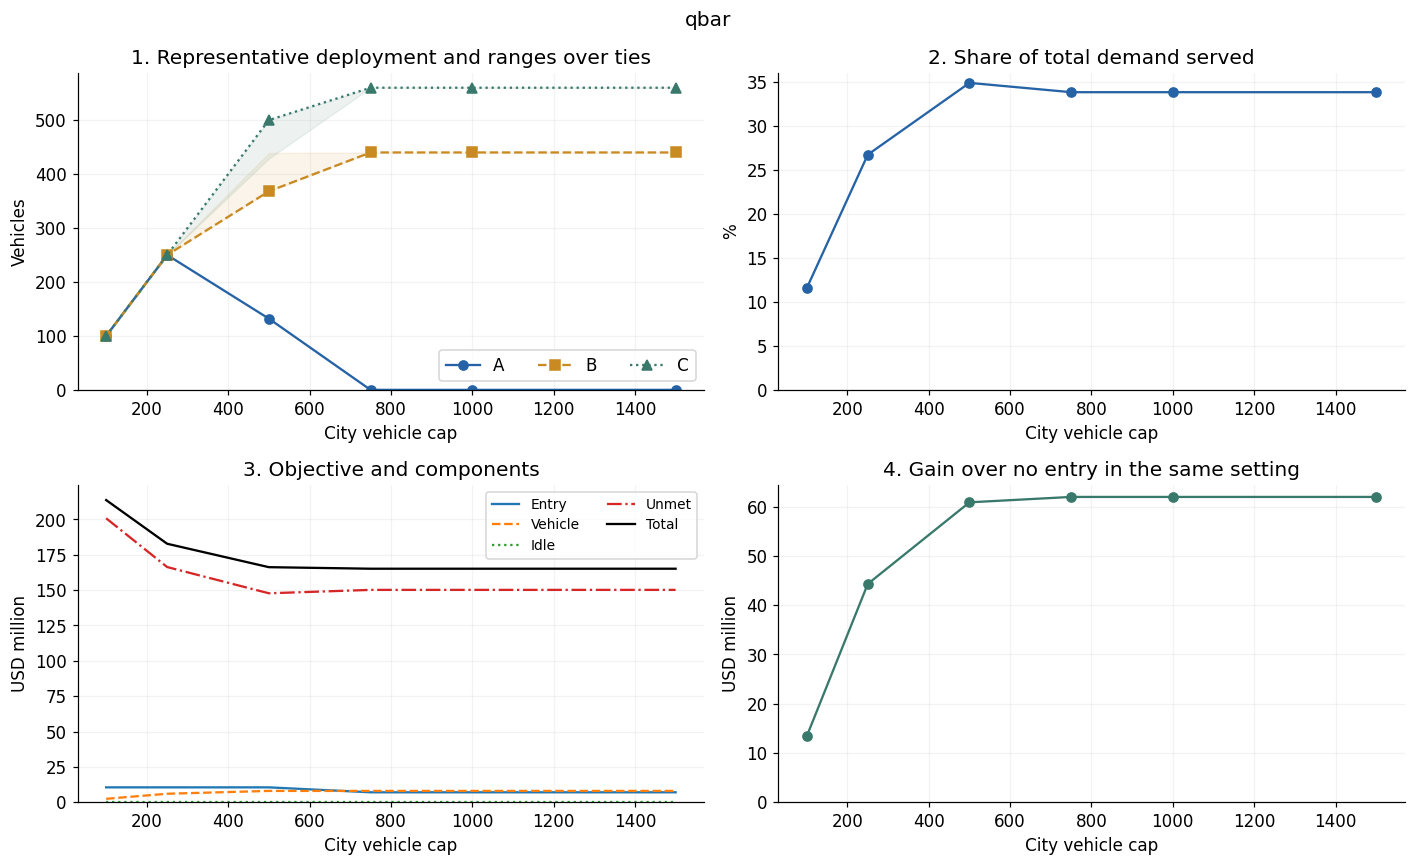

**qbar 주요 비교**

,입력값,대표 배치,최적 q 개수,처리율 (%),평균 유휴,목적함수,개선액
0,100.0,"(100, 100, 100)",1,11.5711,0.000000e+00,2.137295e+08,1.338840e+07
1,250.0,"(250, 250, 250)",1,26.7581,4.927654e+05,1.828245e+08,4.429335e+07
2,500.0,"(132, 368, 500)",72,34.9272,8.273974e+05,1.662639e+08,6.085403e+07
3,750.0,"(0, 440, 560)",1,33.8679,1.067984e+06,1.651697e+08,6.194816e+07
4,1000.0,"(0, 440, 560)",1,33.8679,1.067984e+06,1.651697e+08,6.194816e+07
5,1500.0,"(0, 440, 560)",1,33.8679,1.067984e+06,1.651697e+08,6.194816e+07


입력값,대표 배치,최적 q 개수,평균 수요,평균 처리량,평균 미충족,평균 유휴,처리율 (%),활용률 (%),진입비,차량비,유휴 페널티,미충족 손실,목적함수,미진입 기준,개선액,모든 최적 q의 도시별 최소,모든 최적 q의 도시별 최대,기준 대비 처리량 변화,기준 대비 처리율 변화 (%p),기준 대비 목적함수 변화,기준 대비 개선액 변화
100.0000,"(100, 100, 100)",1,"22,711,788.5265","2,628,000.0000","20,083,788.5265",0.0000,11.5711,100.0000,"10,500,000.0000","2,391,600.0000",0.0000,"200,837,885.2650","213,729,485.2650","227,117,885.2650","13,388,400.0000","(100, 100, 100)","(100, 100, 100)","-5,304,602.5890",-23.3562,"47,465,625.8900","-47,465,625.8900"
250.0000,"(250, 250, 250)",1,"22,711,788.5265","6,077,234.5890","16,634,553.9375","492,765.4110",26.7581,92.4998,"10,500,000.0000","5,979,000.0000",0.0000,"166,345,539.3750","182,824,539.3750","227,117,885.2650","44,293,345.8900","(250, 250, 250)","(250, 250, 250)","-1,855,368.0000",-8.1692,"16,560,680.0000","-16,560,680.0000"
500.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
750.0000,"(0, 440, 560)",1,"22,711,788.5265","7,692,016.0235","15,019,772.5030","1,067,983.9765",33.8679,87.8084,"7,000,000.0000","7,972,000.0000",0.0000,"150,197,725.0300","165,169,725.0300","227,117,885.2650","61,948,160.2350","(0, 440, 560)","(0, 440, 560)","-240,586.5655",-1.0593,"-1,094,134.3450","1,094,134.3450"
"1,000.0000","(0, 440, 560)",1,"22,711,788.5265","7,692,016.0235","15,019,772.5030","1,067,983.9765",33.8679,87.8084,"7,000,000.0000","7,972,000.0000",0.0000,"150,197,725.0300","165,169,725.0300","227,117,885.2650","61,948,160.2350","(0, 440, 560)","(0, 440, 560)","-240,586.5655",-1.0593,"-1,094,134.3450","1,094,134.3450"
"1,500.0000","(0, 440, 560)",1,"22,711,788.5265","7,692,016.0235","15,019,772.5030","1,067,983.9765",33.8679,87.8084,"7,000,000.0000","7,972,000.0000",0.0000,"150,197,725.0300","165,169,725.0300","227,117,885.2650","61,948,160.2350","(0, 440, 560)","(0, 440, 560)","-240,586.5655",-1.0593,"-1,094,134.3450","1,094,134.3450"


**배치 집합 변화가 관찰된 실행 구간:** 100 → 250, 250 → 500, 500 → 750. 인접 실행점 사이를 더 계산하지 않으면 정확한 전환점이라고 단정하지 않는다.

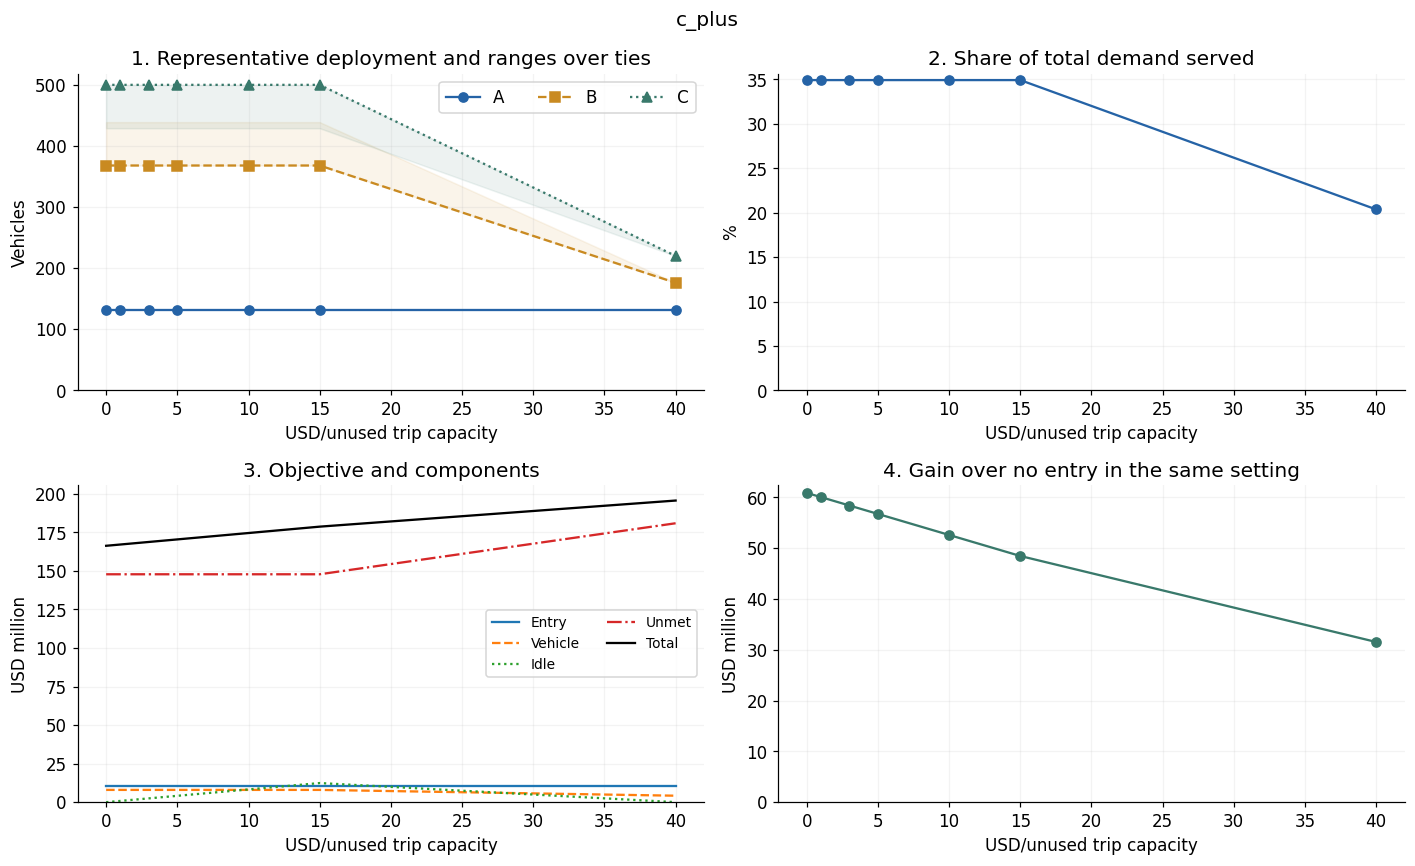

**c_plus 주요 비교**

,입력값,대표 배치,최적 q 개수,처리율 (%),평균 유휴,목적함수,개선액
0,0.0,"(132, 368, 500)",72,34.9272,827397.411,1.662639e+08,6.085403e+07
1,1.0,"(132, 368, 500)",72,34.9272,827397.411,1.670913e+08,6.002663e+07
2,3.0,"(132, 368, 500)",72,34.9272,827397.411,1.687461e+08,5.837183e+07
3,5.0,"(132, 368, 500)",72,34.9272,827397.411,1.704008e+08,5.671704e+07
4,10.0,"(132, 368, 500)",72,34.9272,827397.411,1.745378e+08,5.258005e+07
5,15.0,"(132, 368, 500)",72,34.9272,827397.411,1.786748e+08,4.844306e+07
6,40.0,"(132, 176, 220)",1,20.3631,453.411,1.955970e+08,3.152091e+07


입력값,대표 배치,최적 q 개수,평균 수요,평균 처리량,평균 미충족,평균 유휴,처리율 (%),활용률 (%),진입비,차량비,유휴 페널티,미충족 손실,목적함수,미진입 기준,개선액,모든 최적 q의 도시별 최소,모든 최적 q의 도시별 최대,기준 대비 처리량 변화,기준 대비 처리율 변화 (%p),기준 대비 목적함수 변화,기준 대비 개선액 변화
0.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
1.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000","827,397.4110","147,791,859.3750","167,091,256.7860","227,117,885.2650","60,026,628.4790","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"827,397.4110","-827,397.4110"
3.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000","2,482,192.2330","147,791,859.3750","168,746,051.6080","227,117,885.2650","58,371,833.6570","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"2,482,192.2330","-2,482,192.2330"
5.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000","4,136,987.0550","147,791,859.3750","170,400,846.4300","227,117,885.2650","56,717,038.8350","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"4,136,987.0550","-4,136,987.0550"
10.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000","8,273,974.1100","147,791,859.3750","174,537,833.4850","227,117,885.2650","52,580,051.7800","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"8,273,974.1100","-8,273,974.1100"
15.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000","12,410,961.1650","147,791,859.3750","178,674,820.5400","227,117,885.2650","48,443,064.7250","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"12,410,961.1650","-12,410,961.1650"
40.0000,"(132, 176, 220)",1,"22,711,788.5265","4,624,826.5890","18,086,961.9375",453.4110,20.3631,99.9902,"10,500,000.0000","4,209,216.0000","18,136.4400","180,869,619.3750","195,596,971.8150","227,117,885.2650","31,520,913.4500","(132, 176, 220)","(132, 176, 220)","-3,307,776.0000",-14.5641,"29,333,112.4400","-29,333,112.4400"


**배치 집합 변화가 관찰된 실행 구간:** 15 → 40. 인접 실행점 사이를 더 계산하지 않으면 정확한 전환점이라고 단정하지 않는다.

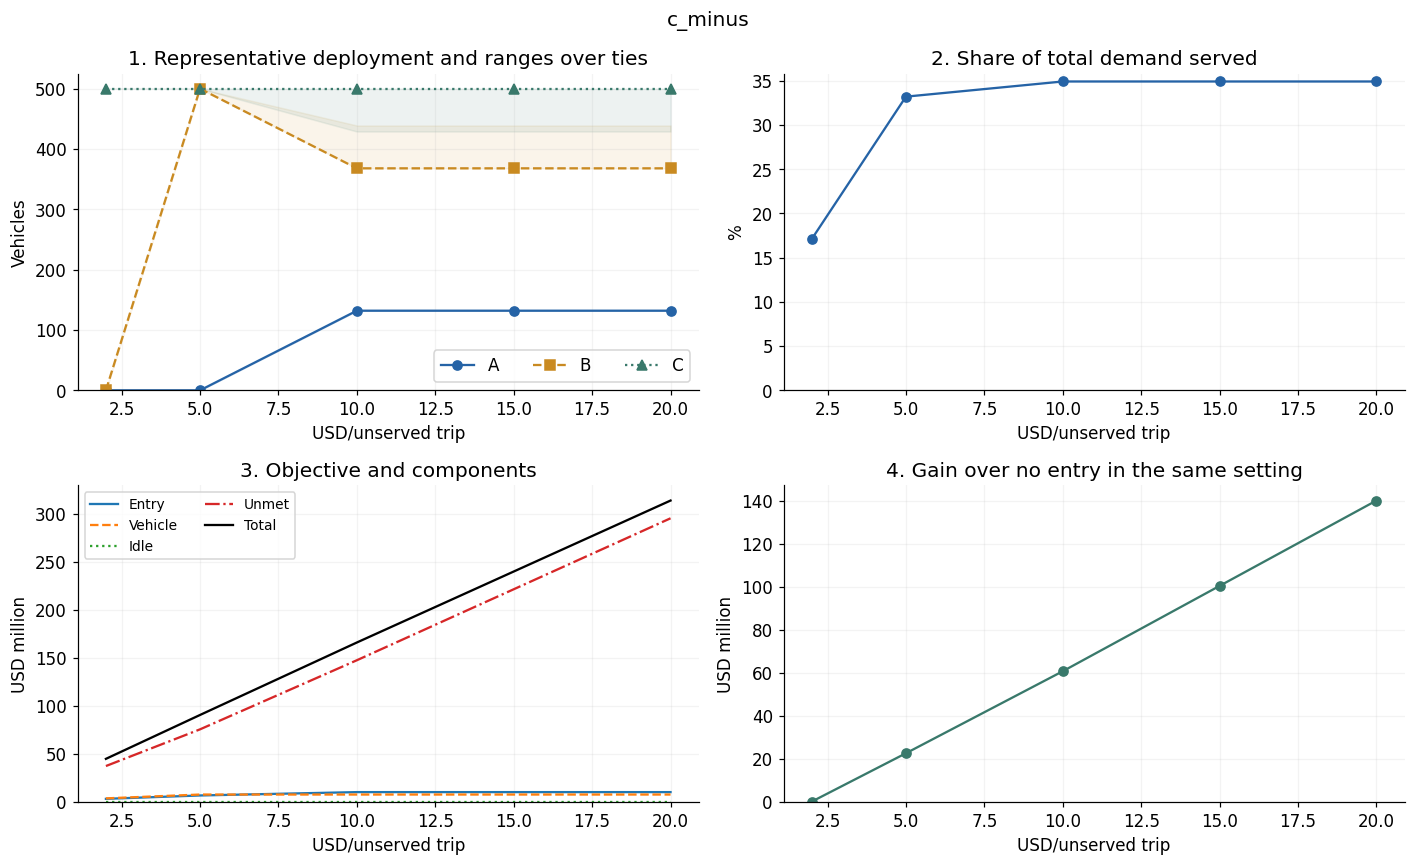

**c_minus 주요 비교**

,입력값,대표 배치,최적 q 개수,처리율 (%),평균 유휴,목적함수,개선액
0,2.0,"(0, 0, 500)",1,17.1245,490727.930,4.513103e+07,2.925441e+05
1,5.0,"(0, 500, 500)",1,33.2132,1216694.064,9.081441e+07,2.274453e+07
2,10.0,"(132, 368, 500)",72,34.9272,827397.411,1.662639e+08,6.085403e+07
3,15.0,"(132, 368, 500)",72,34.9272,827397.411,2.401598e+08,1.005170e+08
4,20.0,"(132, 368, 500)",72,34.9272,827397.411,3.140557e+08,1.401801e+08


입력값,대표 배치,최적 q 개수,평균 수요,평균 처리량,평균 미충족,평균 유휴,처리율 (%),활용률 (%),진입비,차량비,유휴 페널티,미충족 손실,목적함수,미진입 기준,개선액,모든 최적 q의 도시별 최소,모든 최적 q의 도시별 최대,기준 대비 처리량 변화,기준 대비 처리율 변화 (%p),기준 대비 목적함수 변화,기준 대비 개선액 변화
2.0000,"(0, 0, 500)",1,"22,711,788.5265","3,889,272.0700","18,822,516.4565","490,727.9300",17.1245,88.7962,"3,500,000.0000","3,986,000.0000",0.0000,"37,645,032.9130","45,131,032.9130","45,423,577.0530","292,544.1400","(0, 0, 500)","(0, 0, 500)","-4,043,330.5190",-17.8028,"-121,132,826.4620","-60,561,481.7500"
5.0000,"(0, 500, 500)",1,"22,711,788.5265","7,543,305.9360","15,168,482.5905","1,216,694.0640",33.2132,86.1108,"7,000,000.0000","7,972,000.0000",0.0000,"75,842,412.9525","90,814,412.9525","113,558,942.6325","22,744,529.6800","(0, 500, 500)","(0, 500, 500)","-389,296.6530",-1.7141,"-75,449,446.4225","-38,109,496.2100"
10.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
15.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"221,687,789.0625","240,159,789.0625","340,676,827.8975","100,517,038.8350","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"73,895,929.6875","39,663,012.9450"
20.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"295,583,718.7500","314,055,718.7500","454,235,770.5300","140,180,051.7800","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,"147,791,859.3750","79,326,025.8900"


**배치 집합 변화가 관찰된 실행 구간:** 2 → 5, 5 → 10. 인접 실행점 사이를 더 계산하지 않으면 정확한 전환점이라고 단정하지 않는다.

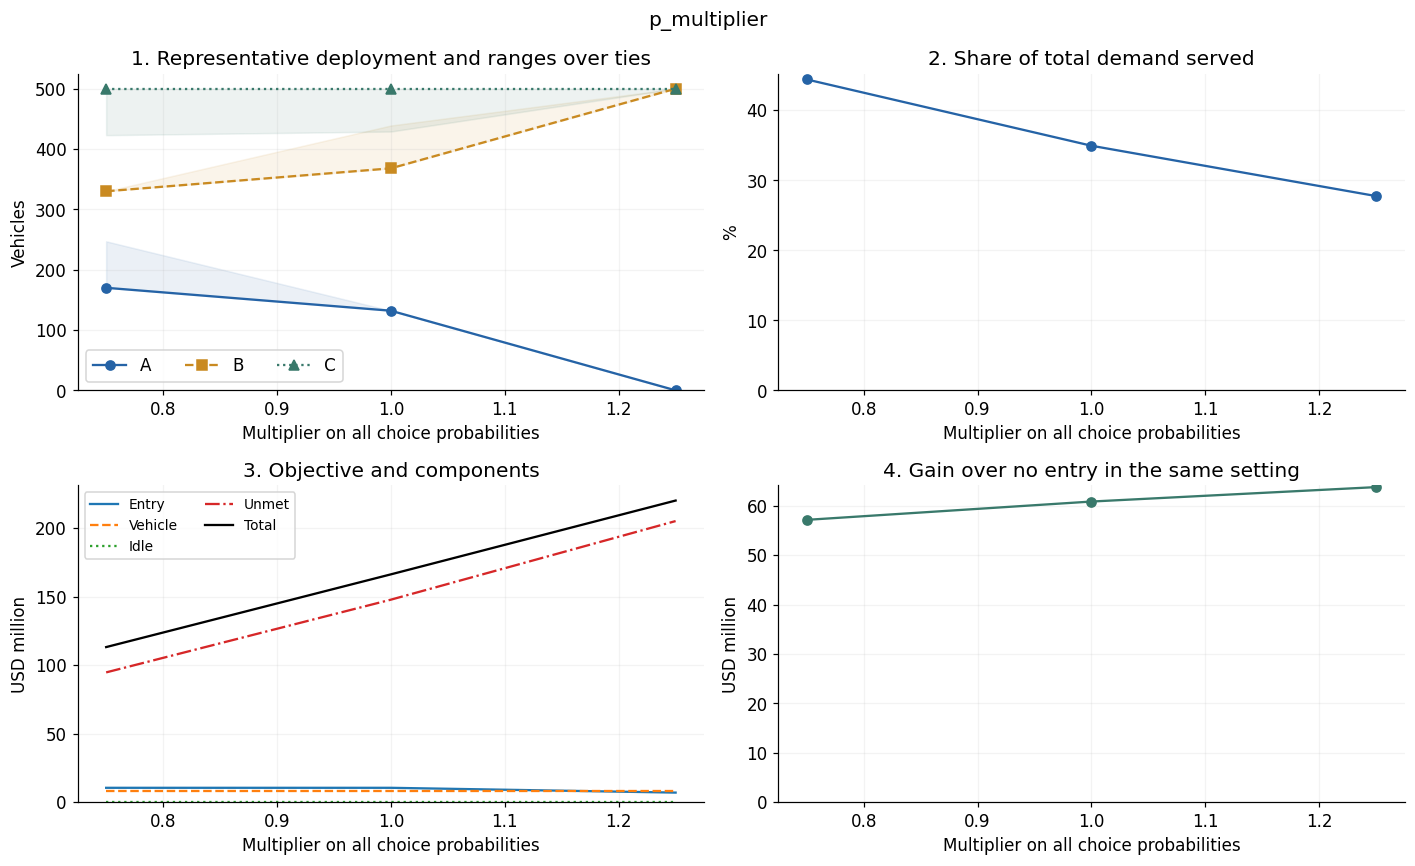

**p_multiplier 주요 비교**

,입력값,대표 배치,최적 q 개수,처리율 (%),평균 유휴,목적함수,개선액
0,0.75,"(170, 330, 500)",78,44.3944,1.197929e+06,1.131897e+08,5.714871e+07
1,1.00,"(132, 368, 500)",72,34.9272,8.273974e+05,1.662639e+08,6.085403e+07
2,1.25,"(0, 500, 500)",1,27.7384,8.851378e+05,2.201207e+08,6.377662e+07


입력값,대표 배치,최적 q 개수,평균 수요,평균 처리량,평균 미충족,평균 유휴,처리율 (%),활용률 (%),진입비,차량비,유휴 페널티,미충족 손실,목적함수,미진입 기준,개선액,모든 최적 q의 도시별 최소,모든 최적 q의 도시별 최대,기준 대비 처리량 변화,기준 대비 처리율 변화 (%p),기준 대비 목적함수 변화,기준 대비 개선액 변화
0.7500,"(170, 330, 500)",78,"17,033,841.3949","7,562,070.6649","9,471,770.7300","1,197,929.3351",44.3944,86.3250,"10,500,000.0000","7,972,000.0000",0.0000,"94,717,707.3000","113,189,707.3000","170,338,413.9487","57,148,706.6487","(170, 330, 423)","(247, 330, 500)","-370,531.9241",9.4671,"-53,074,152.0750","-3,705,319.2412"
1.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
1.2500,"(0, 500, 500)",1,"28,389,735.6581","7,874,862.1575","20,514,873.5006","885,137.8425",27.7384,89.8957,"7,000,000.0000","7,972,000.0000",0.0000,"205,148,735.0062","220,120,735.0062","283,897,356.5813","63,776,621.5750","(0, 500, 500)","(0, 500, 500)","-57,740.4315",-7.1888,"53,856,875.6312","2,922,595.6850"


**배치 집합 변화가 관찰된 실행 구간:** 0.75 → 1, 1 → 1.25. 인접 실행점 사이를 더 계산하지 않으면 정확한 전환점이라고 단정하지 않는다.

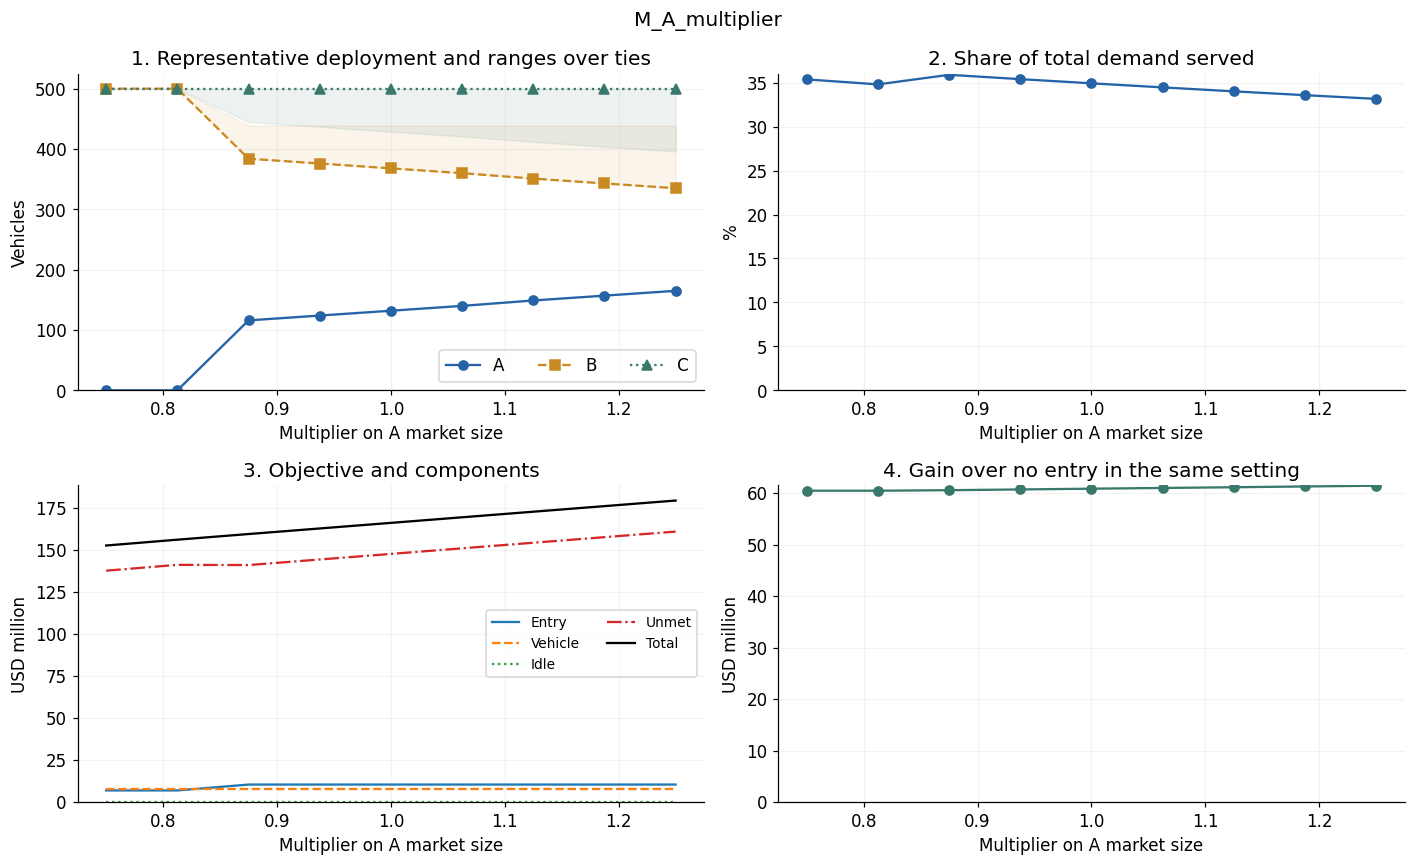

**M_A_multiplier 주요 비교**

,입력값,대표 배치,최적 q 개수,처리율 (%),평균 유휴,목적함수,개선액
0,0.7500,"(0, 500, 500)",1,35.3734,1.216694e+06,1.527870e+08,6.046106e+07
1,0.8125,"(0, 500, 500)",1,34.8074,1.216694e+06,1.562545e+08,6.046106e+07
2,0.8750,"(116, 384, 500)",56,35.8941,8.567245e+05,1.596222e+08,6.056075e+07
3,0.9375,"(124, 376, 500)",64,35.4032,8.420610e+05,1.629430e+08,6.070739e+07
4,1.0000,"(132, 368, 500)",72,34.9272,8.273974e+05,1.662639e+08,6.085403e+07
5,1.0625,"(140, 360, 500)",80,34.4635,8.132303e+05,1.695896e+08,6.099570e+07
6,1.1250,"(149, 351, 500)",89,34.0139,7.989463e+05,1.729142e+08,6.113854e+07
7,1.1875,"(157, 343, 500)",97,33.5791,7.842827e+05,1.762351e+08,6.128517e+07
8,1.2500,"(165, 335, 500)",105,33.1568,7.696192e+05,1.795559e+08,6.143181e+07


입력값,대표 배치,최적 q 개수,평균 수요,평균 처리량,평균 미충족,평균 유휴,처리율 (%),활용률 (%),진입비,차량비,유휴 페널티,미충족 손실,목적함수,미진입 기준,개선액,모든 최적 q의 도시별 최소,모든 최적 q의 도시별 최대,기준 대비 처리량 변화,기준 대비 처리율 변화 (%p),기준 대비 목적함수 변화,기준 대비 개선액 변화
0.7500,"(0, 500, 500)",1,"21,324,809.0745","7,543,305.9360","13,781,503.1385","1,216,694.0640",35.3734,86.1108,"7,000,000.0000","7,972,000.0000",0.0000,"137,815,031.3850","152,787,031.3850","213,248,090.7450","60,461,059.3600","(0, 500, 500)","(0, 500, 500)","-389,296.6530",0.4461,"-13,476,827.9900","-392,966.5300"
0.8125,"(0, 500, 500)",1,"21,671,553.9375","7,543,305.9360","14,128,248.0015","1,216,694.0640",34.8074,86.1108,"7,000,000.0000","7,972,000.0000",0.0000,"141,282,480.0150","156,254,480.0150","216,715,539.3750","60,461,059.3600","(0, 500, 500)","(0, 500, 500)","-389,296.6530",-0.1198,"-10,009,379.3600","-392,966.5300"
0.8750,"(116, 384, 500)",56,"22,018,298.8005","7,903,275.4811","14,115,023.3194","856,724.5189",35.8941,90.2200,"10,500,000.0000","7,972,000.0000",0.0000,"141,150,233.1937","159,622,233.1937","220,182,988.0050","60,560,754.8113","(116, 384, 445)","(116, 439, 500)","-29,327.1079",0.9669,"-6,641,626.1813","-293,271.0787"
0.9375,"(124, 376, 500)",64,"22,365,043.6635","7,917,939.0351","14,447,104.6284","842,060.9649",35.4032,90.3874,"10,500,000.0000","7,972,000.0000",0.0000,"144,471,046.2844","162,943,046.2844","223,650,436.6350","60,707,390.3506","(124, 376, 437)","(124, 439, 500)","-14,663.5539",0.4759,"-3,320,813.0906","-146,635.5394"
1.0000,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)",0.0000,0.0000,0.0000,0.0000
1.0625,"(140, 360, 500)",80,"23,058,533.3895","7,946,769.7260","15,111,763.6635","813,230.2740",34.4635,90.7165,"10,500,000.0000","7,972,000.0000",0.0000,"151,117,636.6350","169,589,636.6350","230,585,333.8950","60,995,697.2600","(140, 360, 421)","(140, 439, 500)","14,167.1370",-0.4638,"3,325,777.2600","141,671.3700"
1.1250,"(149, 351, 500)",89,"23,405,278.2525","7,961,053.6969","15,444,224.5556","798,946.3031",34.0139,90.8796,"10,500,000.0000","7,972,000.0000",0.0000,"154,442,245.5563","172,914,245.5563","234,052,782.5250","61,138,536.9688","(149, 351, 412)","(149, 439, 500)","28,451.1079",-0.9133,"6,650,386.1813","284,511.0788"
1.1875,"(157, 343, 500)",97,"23,752,023.1155","7,975,717.2508","15,776,305.8647","784,282.7492",33.5791,91.0470,"10,500,000.0000","7,972,000.0000",0.0000,"157,763,058.6469","176,235,058.6469","237,520,231.1550","61,285,172.5081","(157, 343, 404)","(157, 439, 500)","43,114.6618",-1.3481,"9,971,199.2719","431,146.6181"
1.2500,"(165, 335, 500)",105,"24,098,767.9785","7,990,380.8048","16,108,387.1738","769,619.1952",33.1568,91.2144,"10,500,000.0000","7,972,000.0000",0.0000,"161,083,871.7375","179,555,871.7375","240,987,679.7850","61,431,808.0475","(165, 335, 396)","(165, 439, 500)","57,778.2157",-1.7704,"13,292,012.3625","577,782.1575"


**배치 집합 변화가 관찰된 실행 구간:** 0.8125 → 0.875, 0.875 → 0.9375, 0.9375 → 1, 1 → 1.0625, 1.0625 → 1.125, 1.125 → 1.1875, 1.1875 → 1.25. 인접 실행점 사이를 더 계산하지 않으면 정확한 전환점이라고 단정하지 않는다.

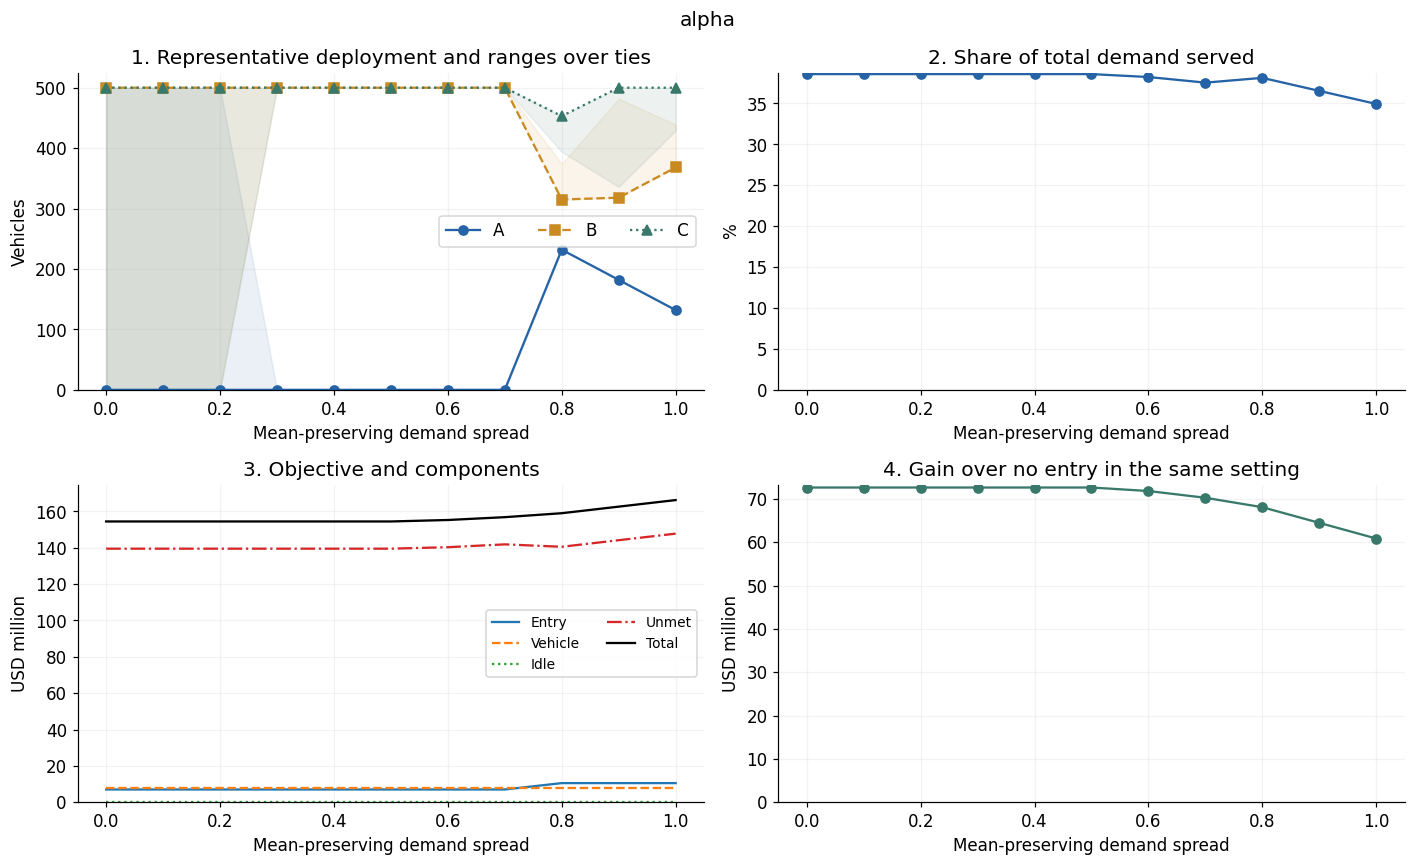

**alpha 주요 비교**

,입력값,대표 배치,최적 q 개수,처리율 (%),평균 유휴,목적함수,개선액
0,0.0,"(0, 500, 500)",3,38.5703,0.0000,1.544899e+08,7.262800e+07
1,0.1,"(0, 500, 500)",3,38.5703,0.0000,1.544899e+08,7.262800e+07
2,0.2,"(0, 500, 500)",3,38.5703,0.0000,1.544899e+08,7.262800e+07
3,0.3,"(0, 500, 500)",1,38.5703,0.0000,1.544899e+08,7.262800e+07
4,0.4,"(0, 500, 500)",1,38.5703,0.0000,1.544899e+08,7.262800e+07
5,0.5,"(0, 500, 500)",1,38.5703,0.0000,1.544899e+08,7.262800e+07
6,0.6,"(0, 500, 500)",1,38.2145,80798.4475,1.552979e+08,7.182002e+07
7,0.7,"(0, 500, 500)",1,37.5280,236724.9487,1.568571e+08,7.026075e+07
8,0.8,"(232, 315, 453)",60,38.1115,104189.3905,1.590318e+08,6.808611e+07
9,0.9,"(182, 318, 500)",165,36.5197,465717.8322,1.626471e+08,6.447082e+07


입력값,대표 배치,최적 q 개수,평균 수요,평균 처리량,평균 미충족,평균 유휴,처리율 (%),활용률 (%),진입비,차량비,유휴 페널티,미충족 손실,목적함수,미진입 기준,개선액,모든 최적 q의 도시별 최소,모든 최적 q의 도시별 최대,기준 대비 처리량 변화,기준 대비 처리율 변화 (%p),기준 대비 목적함수 변화,기준 대비 개선액 변화
0.0000,"(0, 500, 500)",3,"22,711,788.5265","8,760,000.0000","13,951,788.5265",0.0000,38.5703,100.0000,"7,000,000.0000","7,972,000.0000",0.0000,"139,517,885.2650","154,489,885.2650","227,117,885.2650","72,628,000.0000","(0, 0, 0)","(500, 500, 500)","827,397.4110",3.6430,"-11,773,974.1100","11,773,974.1100"
0.1000,"(0, 500, 500)",3,"22,711,788.5265","8,760,000.0000","13,951,788.5265",0.0000,38.5703,100.0000,"7,000,000.0000","7,972,000.0000",0.0000,"139,517,885.2650","154,489,885.2650","227,117,885.2650","72,628,000.0000","(0, 0, 0)","(500, 500, 500)","827,397.4110",3.6430,"-11,773,974.1100","11,773,974.1100"
0.2000,"(0, 500, 500)",3,"22,711,788.5265","8,760,000.0000","13,951,788.5265",0.0000,38.5703,100.0000,"7,000,000.0000","7,972,000.0000",0.0000,"139,517,885.2650","154,489,885.2650","227,117,885.2650","72,628,000.0000","(0, 0, 0)","(500, 500, 500)","827,397.4110",3.6430,"-11,773,974.1100","11,773,974.1100"
0.3000,"(0, 500, 500)",1,"22,711,788.5265","8,760,000.0000","13,951,788.5265",0.0000,38.5703,100.0000,"7,000,000.0000","7,972,000.0000",0.0000,"139,517,885.2650","154,489,885.2650","227,117,885.2650","72,628,000.0000","(0, 500, 500)","(0, 500, 500)","827,397.4110",3.6430,"-11,773,974.1100","11,773,974.1100"
0.4000,"(0, 500, 500)",1,"22,711,788.5265","8,760,000.0000","13,951,788.5265",0.0000,38.5703,100.0000,"7,000,000.0000","7,972,000.0000",0.0000,"139,517,885.2650","154,489,885.2650","227,117,885.2650","72,628,000.0000","(0, 500, 500)","(0, 500, 500)","827,397.4110",3.6430,"-11,773,974.1100","11,773,974.1100"
0.5000,"(0, 500, 500)",1,"22,711,788.5265","8,760,000.0000","13,951,788.5265",0.0000,38.5703,100.0000,"7,000,000.0000","7,972,000.0000",0.0000,"139,517,885.2650","154,489,885.2650","227,117,885.2650","72,628,000.0000","(0, 500, 500)","(0, 500, 500)","827,397.4110",3.6430,"-11,773,974.1100","11,773,974.1100"
0.6000,"(0, 500, 500)",1,"22,711,788.5265","8,679,201.5525","14,032,586.9740","80,798.4475",38.2145,99.0776,"7,000,000.0000","7,972,000.0000",0.0000,"140,325,869.7402","155,297,869.7402","227,117,885.2650","71,820,015.5248","(0, 500, 500)","(0, 500, 500)","746,598.9635",3.2873,"-10,965,989.6348","10,965,989.6348"
0.7000,"(0, 500, 500)",1,"22,711,788.5265","8,523,275.0513","14,188,513.4752","236,724.9487",37.5280,97.2977,"7,000,000.0000","7,972,000.0000",0.0000,"141,885,134.7519","156,857,134.7519","227,117,885.2650","70,260,750.5131","(0, 500, 500)","(0, 500, 500)","590,672.4623",2.6007,"-9,406,724.6231","9,406,724.6231"
0.8000,"(232, 315, 453)",60,"22,711,788.5265","8,655,810.6095","14,055,977.9170","104,189.3905",38.1115,98.8106,"10,500,000.0000","7,972,000.0000",0.0000,"140,559,779.1696","159,031,779.1696","227,117,885.2650","68,086,106.0954","(232, 315, 394)","(232, 374, 453)","723,208.0205",3.1843,"-7,232,080.2054","7,232,080.2054"
0.9000,"(182, 318, 500)",165,"22,711,788.5265","8,294,282.1678","14,417,506.3587","465,717.8322",36.5197,94.6836,"10,500,000.0000","7,972,000.0000",0.0000,"144,175,063.5873","162,647,063.5873","227,117,885.2650","64,470,821.6777","(182, 318, 336)","(182, 482, 500)","361,679.5788",1.5925,"-3,616,795.7877","3,616,795.7877"


**배치 집합 변화가 관찰된 실행 구간:** 0.2 → 0.3, 0.7 → 0.8, 0.8 → 0.9, 0.9 → 1. 인접 실행점 사이를 더 계산하지 않으면 정확한 전환점이라고 단정하지 않는다.

**읽기:** 처리량·처리율·개선액을 함께 보고, 배치 집합 변화 구간을 확인한다.

In [ ]:
for name,values,change,xlabel,divisor in sweep_specs:
    results=run_sweep(name,values,change)
    plot_sweep(name,results,xlabel,divisor)
    if name=='Q':assert np.all(np.diff([a['rep']['cost'] for v,a in results])<=TOL_USD)
    if name=='c_plus' and SHORTAGE:
        assert all(a['rep']['unused']==0 for v,a in results)
        assert all(abs(a['rep']['gain']-b['gain'])<TOL_USD for v,a in results)
    if name in ['M_multiplier','M_A_multiplier','p_multiplier','alpha'] and SHORTAGE:
        assert all(abs(a['rep']['gain']-b['gain'])<TOL_USD for v,a in results)
if SHORTAGE:
    note('**읽기:** Q를 늘리면 1,500대까지 처리량이 늘지만 도시별 상한 때문에 이후에는 멈춘다. '
         '공통 F·K·c−를 바꾸면 개선액은 달라져도 조사 범위의 배치는 유지될 수 있다. '
         'M·p·변동성이 바뀌어도 모든 용량을 쓰는 구간에서는 처리량과 개선액이 같고, 수요 및 처리율·미충족 손실만 달라진다. '
         '**c+가 무의미한 변수가 아니라, 현재 입력에서는 유휴량 O=0이어서 비용에 영향을 주지 않는 것**이다.')
else:
    note('**읽기:** 처리량·처리율·개선액을 함께 보고, 배치 집합 변화 구간을 확인한다.')


### 3-2. 도시별로 하나씩 바꾸기
공통 변화와 다른 질문이다. 예를 들어 A의 F만 바꾸고 B,C의 F는 고정한다.
기준에서 B·C 사이에 동률 배치가 여럿 있으므로, 작은 차이가 동률을 해소하는 현상과 큰 성과 변화를 구분한다.
0인 c+는 배수가 아닌 0·1·3·5를 사용하고, qbar는 문서의 100·500·1000을 사용한다.


**M 한 도시씩 변경**

,변경 도시,설정,설정 의미,대표 배치,최적 q 개수,처리율 (%),목적함수,개선액
0,A,0.75,기준 배율,"(0, 500, 500)",1,35.373,1.527870e+08,6.046106e+07
1,A,1.00,기준 배율,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
2,A,1.25,기준 배율,"(165, 335, 500)",105,33.157,1.795559e+08,6.143181e+07
3,B,0.75,기준 배율,"(170, 330, 500)",1,37.597,1.483001e+08,5.974682e+07
4,B,1.00,기준 배율,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
5,B,1.25,기준 배율,"(0, 500, 500)",1,31.596,1.833754e+08,6.281344e+07
6,C,0.75,기준 배율,"(132, 440, 428)",16,38.479,1.435307e+08,5.974845e+07
7,C,1.00,기준 배율,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
8,C,1.25,기준 배율,"(132, 368, 500)",72,31.993,1.891394e+08,6.181721e+07


**kappa 한 도시씩 변경**

,변경 도시,설정,설정 의미,대표 배치,최적 q 개수,처리율 (%),목적함수,개선액
9,A,0.75,기준 배율,"(0, 500, 500)",1,33.213,1.666568e+08,6.046106e+07
10,A,1.00,기준 배율,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
11,A,1.25,기준 배율,"(264, 236, 500)",204,36.199,1.633756e+08,6.374231e+07
12,B,0.75,기준 배율,"(266, 234, 500)",1,32.602,1.715448e+08,5.557309e+07
13,B,1.00,기준 배율,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
14,B,1.25,기준 배율,"(148, 352, 500)",1,37.579,1.602420e+08,6.687587e+07
15,C,0.75,기준 배율,"(267, 440, 293)",1,32.143,1.725876e+08,5.453033e+07
16,C,1.00,기준 배율,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
17,C,1.25,기준 배율,"(132, 368, 500)",1,38.494,1.581630e+08,6.895493e+07


**F 한 도시씩 변경**

...

**qbar 한 도시씩 변경**

,변경 도시,설정,설정 의미,대표 배치,최적 q 개수,처리율 (%),목적함수,개선액
57,A,100.0,절대값,"(0, 500, 500)",1,33.213,1.666568e+08,6.046106e+07
58,A,500.0,절대값,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
59,A,1000.0,절대값,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
60,B,100.0,절대값,"(400, 100, 500)",1,32.767,1.711706e+08,5.594725e+07
61,B,500.0,절대값,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
62,B,1000.0,절대값,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
63,C,100.0,절대값,"(400, 500, 100)",61,31.731,1.735230e+08,5.359487e+07
64,C,500.0,절대값,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
65,C,1000.0,절대값,"(0, 440, 560)",1,33.868,1.651697e+08,6.194816e+07


**p 한 도시씩 변경**

,변경 도시,설정,설정 의미,대표 배치,최적 q 개수,처리율 (%),목적함수,개선액
66,A,0.75,기준 배율,"(0, 500, 500)",1,35.373,1.527870e+08,6.046106e+07
67,A,1.00,기준 배율,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
68,A,1.25,기준 배율,"(165, 335, 500)",105,33.157,1.795559e+08,6.143181e+07
69,B,0.75,기준 배율,"(170, 330, 500)",1,37.597,1.483001e+08,5.974682e+07
70,B,1.00,기준 배율,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
71,B,1.25,기준 배율,"(0, 500, 500)",1,31.596,1.833754e+08,6.281344e+07
72,C,0.75,기준 배율,"(132, 440, 428)",16,38.479,1.435307e+08,5.974845e+07
73,C,1.00,기준 배율,"(132, 368, 500)",72,34.927,1.662639e+08,6.085403e+07
74,C,1.25,기준 배율,"(132, 368, 500)",72,31.993,1.891394e+08,6.181721e+07


변수,변경 도시,설정,설정 의미,대표 배치,최적 q 개수,평균 수요,평균 처리량,평균 미충족,평균 유휴,처리율 (%),활용률 (%),진입비,차량비,유휴 페널티,미충족 손실,목적함수,미진입 기준,개선액,모든 최적 q의 도시별 최소,모든 최적 q의 도시별 최대,기준 조건 재평가 개선액,기준 조건에서 실행 가능
M,A,0.7500,기준 배율,"(0, 500, 500)",1,"21,324,809.0745","7,543,305.9360","13,781,503.1385","1,216,694.0640",35.3734,86.1108,"7,000,000.0000","7,972,000.0000",0.0000,"137,815,031.3850","152,787,031.3850","213,248,090.7450","60,461,059.3600","(0, 500, 500)","(0, 500, 500)","60,461,059.3600",True
M,A,1.0000,기준 배율,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)","60,854,025.8900",True
M,A,1.2500,기준 배율,"(165, 335, 500)",105,"24,098,767.9785","7,990,380.8048","16,108,387.1738","769,619.1952",33.1568,91.2144,"10,500,000.0000","7,972,000.0000",0.0000,"161,083,871.7375","179,555,871.7375","240,987,679.7850","61,431,808.0475","(165, 335, 396)","(165, 439, 500)","60,564,945.8900",True
M,B,0.7500,기준 배율,"(170, 330, 500)",1,"20,804,691.7800","7,821,882.3325","12,982,809.4475","938,117.6675",37.5967,89.2909,"10,500,000.0000","7,972,000.0000",0.0000,"129,828,094.4750","148,300,094.4750","208,046,917.8000","59,746,823.3250","(170, 330, 500)","(170, 330, 500)","60,521,145.8900",True
M,B,1.0000,기준 배율,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)","60,854,025.8900",True
M,B,1.2500,기준 배율,"(0, 500, 500)",1,"24,618,885.2730","7,778,544.1400","16,840,341.1330","981,455.8600",31.5958,88.7962,"7,000,000.0000","7,972,000.0000",0.0000,"168,403,411.3300","183,375,411.3300","246,188,852.7300","62,813,441.4000","(0, 500, 500)","(0, 500, 500)","60,461,059.3600",True
M,C,0.7500,기준 배율,"(132, 440, 428)",16,"20,327,917.5934","7,822,045.3471","12,505,872.2462","937,954.6529",38.4793,89.2928,"10,500,000.0000","7,972,000.0000",0.0000,"125,058,722.4625","143,530,722.4625","203,279,175.9337","59,748,453.4712","(132, 440, 413)","(147, 440, 428)","60,848,987.9900",True
M,C,1.0000,기준 배율,"(132, 368, 500)",72,"22,711,788.5265","7,932,602.5890","14,779,185.9375","827,397.4110",34.9272,90.5548,"10,500,000.0000","7,972,000.0000",0.0000,"147,791,859.3750","166,263,859.3750","227,117,885.2650","60,854,025.8900","(132, 368, 429)","(132, 439, 500)","60,854,025.8900",True
M,C,1.2500,기준 배율,"(132, 368, 500)",72,"25,095,659.4596","8,028,920.6065","17,066,738.8531","731,079.3935",31.9933,91.6543,"10,500,000.0000","7,972,000.0000",0.0000,"170,667,388.5312","189,139,388.5312","250,956,594.5963","61,817,206.0650","(132, 368, 429)","(132, 439, 500)","60,854,025.8900",True
kappa,A,0.7500,기준 배율,"(0, 500, 500)",1,"22,711,788.5265","7,543,305.9360","15,168,482.5905","1,216,694.0640",33.2132,86.1108,"7,000,000.0000","7,972,000.0000",0.0000,"151,684,825.9050","166,656,825.9050","227,117,885.2650","60,461,059.3600","(0, 500, 500)","(0, 500, 500)","60,461,059.3600",True


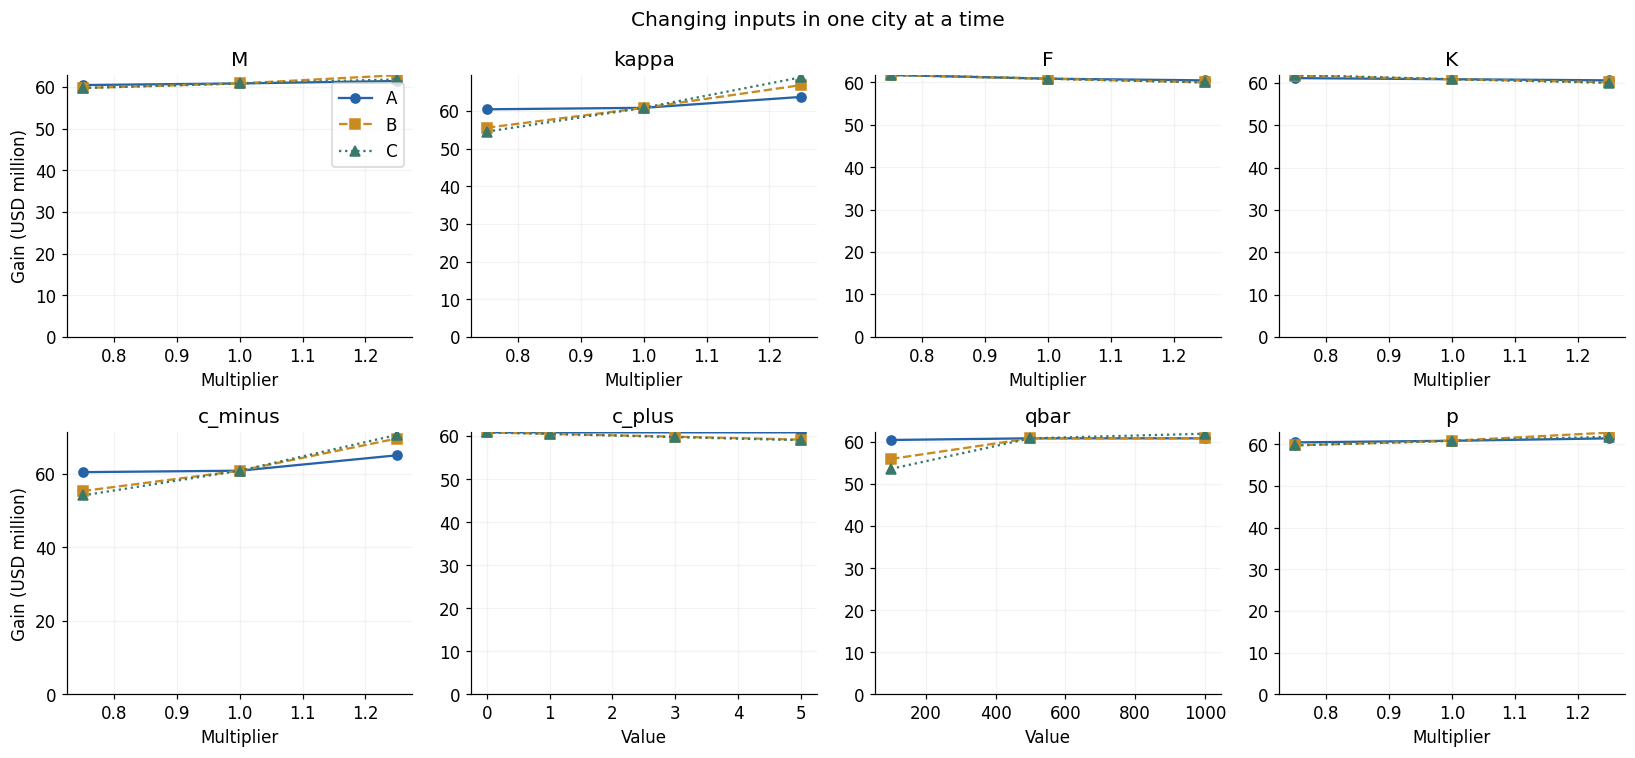

한 도시의 F 또는 K가 낮아지거나 κ 또는 c−가 높아지면 그 도시로 차량이 이동한다. 이 입력에서는 한 도시의 M·p 변경도 배치를 바꾼다(수요가 용량 근처이므로). 한 도시에만 c+를 1 이상 주면 B·C 사이의 동률이 해소되어 최적해가 유일해지는 경우가 많다. 공통 입력 실험에서 배치가 유지된다고 도시별 차이에도 둔감하다고 결론내리면 안 된다.

In [ ]:
city_rows=[]
for key in ['M','kappa','F','K','c_minus','c_plus','qbar','p']:
    for c,city in enumerate(cities):
        levels=[0,1,3,5] if key=='c_plus' else ([100,500,1000] if key=='qbar' else [.75,1.,1.25])
        for level in levels:
            d=deepcopy(BASE)
            if key=='p':d['p'][:,c]=BASE['p'][:,c]*level
            else:d[key][c]=level if key in ['qbar','c_plus'] else BASE[key][c]*level
            a=solve(d,f'{city}:{key}={level}')
            row={'변수':key,'변경 도시':city,'설정':level,'설정 의미':'절대값' if key in ['qbar','c_plus'] else '기준 배율',**report_row(a)}
            # 배치가 기준 조건에서 얼마나 좋은지도 동일한 기준 입력으로 평가한다.
            # qbar가 늘어난 경우에는 기준에서 불가능할 수 있으므로 강제로 비교하지 않는다.
            feasible=np.all(np.array(a['rep']['q'])<=BASE['qbar']) and sum(a['rep']['q'])<=BASE['Q']
            row['기준 조건 재평가 개선액']=evaluate(BASE,a['rep']['q'])['gain'] if feasible else np.nan
            row['기준 조건에서 실행 가능']=feasible
            city_rows.append(row)
city_sensitivity=pd.DataFrame(city_rows)
for key,group in city_sensitivity.groupby('변수',sort=False):
    show(key+' 한 도시씩 변경',group[['변경 도시','설정','설정 의미','대표 배치','최적 q 개수','처리율 (%)','목적함수','개선액']].round(3))
detail('도시별 민감도: 전체 비용·성과·동률 배치 범위',city_sensitivity)
fig,axes=plt.subplots(2,4,figsize=(15,7))
for ax,(key,group) in zip(axes.flat,city_sensitivity.groupby('변수',sort=False)):
    for c,city in enumerate(cities):
        g=group[group['변경 도시']==city]
        ax.plot(g['설정'],g['개선액']/1e6,marker=['o','s','^'][c],linestyle=['-','--',':'][c],color=COLORS[c],label=city)
    ax.set_title(key);ax.set_xlabel(L('절대값' if key in ['qbar','c_plus'] else '기준 배율','Value' if key in ['qbar','c_plus'] else 'Multiplier'))
    ax.grid(alpha=.15);ax.set_ylim(bottom=0)
for ax in axes[:,0]:ax.set_ylabel(L('개선액 (백만 USD)','Gain (USD million)'))
axes[0,0].legend();fig.suptitle(L('한 도시의 입력만 바꿨을 때의 개선액','Changing inputs in one city at a time'))
showfig(fig,'15_city_sensitivity')
note('한 도시의 F 또는 K가 낮아지거나 κ 또는 c−가 높아지면 그 도시로 차량이 이동한다. '
     '이 입력에서는 한 도시의 M·p 변경도 배치를 바꾼다(수요가 용량 근처이므로). '
     '한 도시에만 c+를 1 이상 주면 B·C 사이의 동률이 해소되어 최적해가 유일해지는 경우가 많다. '
     '공통 입력 실험에서 배치가 유지된다고 도시별 차이에도 둔감하다고 결론내리면 안 된다.')

## 4. 평균 수요 방식과 시나리오 표본 반복
### 4-1. 평균 수요 방식도 같은 평가 시나리오에서 비교
무작위 p의 시나리오 평균을 도시별로 취해 시나리오 1개로 풀고, 그 배치를 원래 10개 시나리오에서 평가한다.
작은 사례의 추가 손실 0~16 USD를 이 사례에 옮겨 쓰지 않는다.


In [ ]:
mean_data=deepcopy(BASE);mean_data['p']=BASE['p'].mean(axis=0,keepdims=True)
mean_answer=solve(mean_data,'annual mean demand')
mean_evaluations=[evaluate(BASE,qq) for qq in mean_answer['oracle']['samples']]
if SHORTAGE:
    assert mean_answer['oracle']['count']==3
    assert all(abs(r['cost']-b['cost'])<TOL_USD for r in mean_evaluations)
show(f'평균 수요 방식의 모든 최적 배치를 원래 {S}개 시나리오에서 평가',pd.DataFrame([
 {'q':r['q'],'공통 시나리오 평가비용':r['cost'],'시나리오 최적 대비 추가비용':r['cost']-b['cost'],'처리율 (%)':100*r['service_rate']} for r in mean_evaluations]))
extra=max(r['cost']-b['cost'] for r in mean_evaluations)
note(f'평균 수요 방식 배치의 시나리오 최적 대비 추가비용은 최대 {extra:,.2f} USD이다. '
     +('0인 이유는 불확실성이 일반적으로 중요하지 않다는 뜻이 아니라, 현재의 충분한 미충족 수요 구간에서 손실이 수요에 대해 선형이기 때문이다.' if SHORTAGE else '수요가 용량 근처인 도시가 있으면 평균만 쓴 배치가 손실을 낼 수 있다.'))

**평균 수요 방식의 모든 최적 배치를 원래 10개 시나리오에서 평가**

,q,공통 시나리오 평가비용,시나리오 최적 대비 추가비용,처리율 (%)
0,"(0, 500, 500)",1.666568e+08,392966.53,33.213174
1,"(500, 0, 500)",1.720506e+08,5786775.51,30.838280
2,"(500, 500, 0)",1.744030e+08,8139157.55,29.802527


평균 수요 방식 배치의 시나리오 최적 대비 추가비용은 최대 8,139,157.55 USD이다. 수요가 용량 근처인 도시가 있으면 평균만 쓴 배치가 손실을 낼 수 있다.

### 4-2. 50·100·500개 시나리오, 각 5개 시드
문서의 후속 시나리오 수를 사용한다. 정의한 10개 시나리오에서 동일 확률로 복원추출한다.
샘플에 같은 시나리오가 반복되는 것은 허용되며, 각 샘플 행의 가중치는 $1/|S|$이다.
이는 **가정한 10개 시나리오 분포의 표본 안정성 검사**이며 실제 수요 분포를 검증하거나 연속 수요를 학습하는 실험이 아니다.
표본 평균의 변화와 배치 성능의 변화를 분리하기 위해, 구한 배치를 원래 10개 시나리오 전체에서 다시 평가한다.


**시나리오 수 × 시드 반복 결과**

,S,seed,고유 시나리오 수,"표본 평균 p (A,B,C)",대표 배치,최적 q 개수,표본 평균 수요,표본 목적함수,표본 처리율 (%),공통 분포 평가 목적함수,공통 분포 평가 개선액,공통 분포 추가비용
0,50,590,10,"(0.009, 0.009, 0.011)","(132, 440, 428)",1,2.285819e+07,1.650570e+08,35.871998,1.662689e+08,60848987.99,5037.90
1,50,591,10,"(0.011, 0.009, 0.009)","(329, 176, 495)",1,2.212617e+07,1.633715e+08,34.512179,1.679896e+08,59128305.89,1725720.00
2,50,592,10,"(0.01, 0.011, 0.012)","(0, 500, 500)",1,2.576314e+07,1.947086e+08,30.234994,1.666568e+08,60461059.36,392966.53
3,50,593,10,"(0.011, 0.009, 0.009)","(324, 176, 500)",1,2.189501e+07,1.600872e+08,35.320807,1.679458e+08,59172105.89,1681920.00
4,50,594,10,"(0.011, 0.009, 0.01)","(132, 368, 500)",1,2.244595e+07,1.647692e+08,34.822433,1.662639e+08,60854025.89,0.00
5,100,590,10,"(0.009, 0.009, 0.01)","(132, 439, 429)",1,2.249026e+07,1.618388e+08,36.253833,1.662639e+08,60854025.89,0.00
6,100,591,10,"(0.01, 0.009, 0.009)","(324, 176, 500)",1,2.184493e+07,1.593408e+08,35.514171,1.679458e+08,59172105.89,1681920.00
7,100,592,10,"(0.01, 0.011, 0.011)","(0, 500, 500)",1,2.414693e+07,1.786986e+08,32.195698,1.666568e+08,60461059.36,392966.53
8,100,593,10,"(0.01, 0.009, 0.009)","(132, 368, 500)",1,2.198555e+07,1.599969e+08,35.628205,1.662639e+08,60854025.89,0.00
9,100,594,10,"(0.01, 0.01, 0.01)","(132, 368, 500)",1,2.226102e+07,1.618476e+08,35.593436,1.662639e+08,60854025.89,0.00


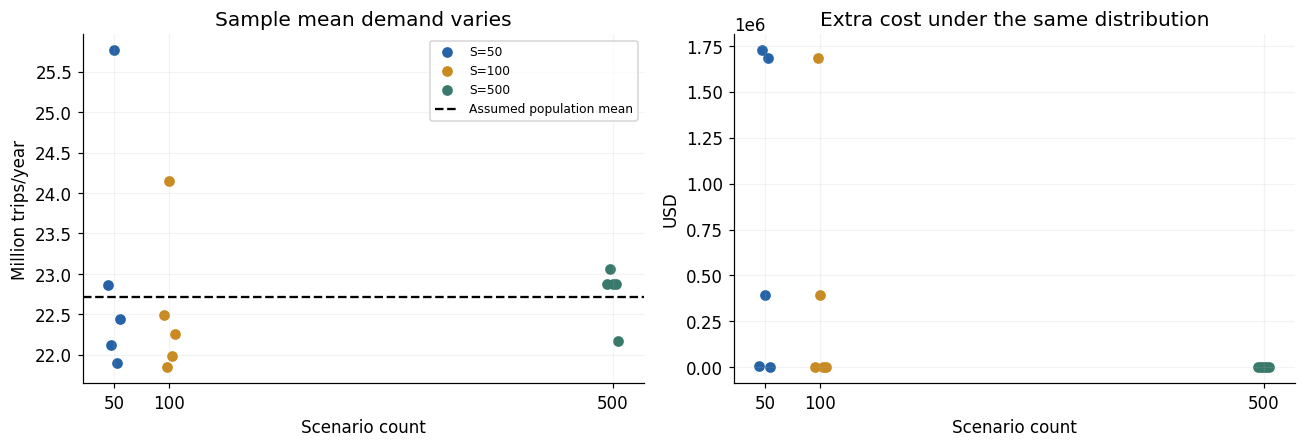

표본 목적함수가 달라져도 배치가 나빠졌다는 뜻은 아니다. 뽑힌 수요의 평균이 달라져 미진입 기준도 달라진다. 5개 시드만으로 일반적인 수렴 속도를 주장하지 않는다.

In [ ]:
sample_rows=[];SEEDS=[590,591,592,593,594]
for ns in [50,100,500]:
    for seed in SEEDS:
        rng=np.random.default_rng(seed);indices=rng.integers(0,len(BASE['p']),size=ns)
        d=deepcopy(BASE);d['p']=BASE['p'][indices].copy()
        a=solve(d,f'sample S={ns} seed={seed}');pop=evaluate(BASE,a['rep']['q'])
        sample_rows.append({'S':ns,'seed':seed,'고유 시나리오 수':int(len(np.unique(indices))),
            '표본 평균 p (A,B,C)':tuple(np.round(d['p'].mean(axis=0),3)),'대표 배치':a['rep']['q'],'최적 q 개수':a['oracle']['count'],
            '표본 평균 수요':a['rep']['demand'],'표본 목적함수':a['rep']['cost'],'표본 처리율 (%)':100*a['rep']['service_rate'],
            '공통 분포 평가 목적함수':pop['cost'],'공통 분포 평가 개선액':pop['gain'],
            '공통 분포 추가비용':pop['cost']-b['cost']})
sample_results=pd.DataFrame(sample_rows)
show('시나리오 수 × 시드 반복 결과',sample_results)
if SHORTAGE:assert np.allclose(sample_results['공통 분포 추가비용'],0,atol=TOL_USD,rtol=0)
fig,axes=plt.subplots(1,2,figsize=(12,4.2))
for c,ns in enumerate([50,100,500]):
    g=sample_results[sample_results['S']==ns]
    axes[0].scatter(np.full(len(g),ns)+np.linspace(-5,5,len(g)),g['표본 평균 수요']/1e6,label=f'S={ns}',color=COLORS[c])
    axes[1].scatter(np.full(len(g),ns)+np.linspace(-5,5,len(g)),g['공통 분포 추가비용'],color=COLORS[c])
axes[0].axhline(b['demand']/1e6,color='black',linestyle='--',label=L('가정 분포 평균','Assumed population mean'))
axes[0].set_ylabel(L('백만 건/년','Million trips/year'));axes[0].legend(fontsize=8)
axes[0].set_title(L('표본 평균 수요는 달라진다','Sample mean demand varies'))
axes[1].set_ylabel('USD');axes[1].set_title(L('같은 분포에서 평가한 추가비용','Extra cost under the same distribution'))
for ax in axes:ax.set_xticks([50,100,500]);ax.set_xlabel(L('시나리오 수','Scenario count'));ax.grid(alpha=.15)
showfig(fig,'17_sampling')
note('표본 목적함수가 달라져도 배치가 나빠졌다는 뜻은 아니다. 뽑힌 수요의 평균이 달라져 미진입 기준도 달라진다. '
     +('이 실험에서는 각 표본에서도 수요가 모든 용량보다 커서 동률 배치 집합과 공통 분포 평가 성과가 유지된다. ' if SHORTAGE else '')
     +'5개 시드만으로 일반적인 수렴 속도를 주장하지 않는다.')

## 5. 결과 해석과 저장
- **도시별 수요 차이가 배치에 반영되는 조건:** 수요가 용량과 같은 규모일 때다. v2(p ≥ 0.02)에서는 최소 수요조차 용량의 2.6배여서 M·p가 배치를 바꾸지 못했고, v3(p ≤ 0.02)에서는 A 132 / B·C 868의 비대칭 배치와 세 도시 진입이 나온다.
- **M 축소와 p 축소는 같은 실험이다:** $D=Mp$만 모델에 들어가므로 둘을 구별할 수 없다. 공통 M 배율·p 배율 민감도가 이를 보여 준다(같은 배율에서 같은 배치·개선액).
- **q̄·Q·M은 별도 실험이 아니라 민감도 항목이다:** 다만 v2의 범위(q̄ ≤ 1,000, Q ≤ 2,000, M ≥ 0.75배)에서는 공급 부족 구간을 벗어나지 못해 변화가 보이지 않았다. v3에서는 같은 범위에서 배치가 움직인다.
- **동률이 남는 이유:** 시나리오 10개가 등확률이고 c+=0이어서 차량 한 대의 가치가 P(수요 > 용량)의 0.1 단위 계단함수다. B·C의 넓은 구간이 같은 단(8/10)에 있어 72개가 동률이다. 시나리오 수를 늘리거나 c+>0을 두면 동률이 줄어든다(도시별 c+ 실험 참고).
- **성과와 결정의 민감도는 다르다:** 공통 F·K를 ±25% 바꾸면 개선액은 달라지지만, F가 약 3.9M USD를 넘을 때만 배치가 바뀐다(A 제외). c−는 배치에 크게 작용한다(2 → 한 도시, 5 → 두 도시, 10 이상 → 세 도시).
- **c+의 효과:** 공통 c+는 배치를 바꾸지 않고 개선액만 줄인다(유휴 827,397건에 비례). 한 도시에만 c+를 주면 B·C 동률이 해소된다.
- **표본 안정성:** 50개 표본에서는 배치가 시드에 따라 달라진다. 이 입력에서는 시나리오 수가 결과에 실질적으로 영향을 준다.
- **실험의 한계:** p 후보값을 손익 경계 근처로 낮춘 것은 문서 값이 아니라 모델 반응을 보기 위한 가정이다. 문헌 참고 입력의 규모와 모델 구조를 점검한 결과이며 실제 최적 도시·차량 수에 대한 권고가 아니다.


In [ ]:
assert all(all(r['checks'].values()) for r in SOLVE_LOG)
assert all(r['gap']<=1e-8 for r in SOLVE_LOG)
all_sensitivity=pd.concat([table.assign(실험=name) for name,table in sensitivity_tables.items()],ignore_index=True)
note(f'**실행 완료:** 중복 입력 캐시를 제외한 MILP·DP 대조 **{len(SOLVE_LOG)}회 PASS**, '
     f'엣지 케이스 **{len(edge_answers)}개 PASS**, 공통/추가 민감도 **{len(all_sensitivity)}행**, '
     f'도시별 민감도 **{len(city_sensitivity)}행**, 시나리오 반복 **{len(sample_results)}행**. '
     f'Python {sys.version.split()[0]}, SciPy {scipy.__version__}.')
# 필요하면 True로 바꾸어 Colab 작업 폴더에 CSV를 저장합니다.
EXPORT_CSV=False
if EXPORT_CSV:
    edge_table.to_csv('annual_v3_edges.csv',index=False,encoding='utf-8-sig')
    all_sensitivity.to_csv('annual_v3_sensitivity.csv',index=False,encoding='utf-8-sig')
    city_sensitivity.to_csv('annual_v3_city_sensitivity.csv',index=False,encoding='utf-8-sig')
    sample_results.to_csv('annual_v3_sampling.csv',index=False,encoding='utf-8-sig')